In [1]:
import os
import lmdb
import json
import pickle
import rasterio
import datetime
import numpy as np
import matplotlib.pyplot as plt

from shapely.geometry import MultiPolygon
import geopandas as gpd
import pandas as pd

from tqdm import tqdm

fd_pdata = '/p/scratch/hai_dm4eo/liu_ch/data/WeakFT'
fd_lmdb = '/p/scratch/hai_ws4eo/liu_ch/data/WeakFT/weak_lmdbs'
fd_used_csv = '/p/project1/hai_ws4eo/liu_ch/Weak_FT/segment-anything-2/data_preparation/weak_label_downloading/centroids_used'

S2C_MEAN = [1605.57504906, 1390.78157673, 1314.8729939, 1363.52445545, 1549.44374991, 2091.74883118, 2371.7172463, 2299.90463006, 2560.29504086, 830.06605044, 22.10351321, 2177.07172323, 1524.06546312]
S2C_STD = [786.78685367, 850.34818441, 875.06484736, 1138.84957046, 1122.17775652, 1161.59187054, 1274.39184232, 1248.42891965, 1345.52684884, 577.31607053, 51.15431158, 1336.09932639, 1136.53823676]

In [2]:
def get_complete_set(fdir, n=4):
    fdir = os.path.join(fdir, 'data')   
    ndirs = [int(d) for d in os.listdir(fdir) if '.' not in d]
    ndirs.sort()
    complete_set = []    # s1, s2, lc
    for nd in ndirs:
        fp = os.path.join(fdir, f'{nd:07d}')
        fsubs = os.listdir(fp)
        if len(fsubs) == n:
            complete_set.append(nd)
    return complete_set, len(ndirs)


def save_meta_info(fdir, complete_set, keys=['s1', 's2'], lc_keys=None):
    # Initialize lists to store the data
    names = {key: [] for key in keys}
    coords = []

    # Iterate through the complete_set
    for nd in complete_set:
        fp = os.path.join(fdir, 'data', f'{nd:07d}')
        name = {key: None for key in keys}
        
        # List the subdirectories and files
        fsubs = os.listdir(fp)
        
        # Find the s1 and s2 file names
        for fs in fsubs:
            if fs.endswith('.tif'):
                if lc_keys is None: continue
            else:
                name[fs] = os.listdir(os.path.join(fp, fs))[0]
        for k in name:
            assert name[k] is not None, f'Error: {k}'
            names[k].append(name[k])

    # Create a DataFrame
    df = pd.DataFrame({
        'id': complete_set,
        **names,
    })

    # Read the CSV file
    csv_path = os.path.join(fdir, 'Downloaded_file_info_lc.csv')
    csv_df = pd.read_csv(csv_path)

    # Fetch the corresponding coordinates
    coords, lons, lats = [], [], []
    for id in complete_set:
        coord_row = csv_df[csv_df['img_id'] == id].coords
        coords_ = json.loads(coord_row.iloc[0])
        coords.append(coords_)
        coords_ = np.array(coords_)
        center = [coords_[:, i].mean() for i in range(2)]
        lons.append(center[0])
        lats.append(center[1])

    # Add the coordinates to the DataFrame
    df['coords'] = coords
    df['lon'] = lons
    df['lat'] = lats

    # save the DataFrame
    df.to_csv(os.path.join(fdir, 'Complete_file_info.csv'), index=False)

    return df

In [3]:
def plot_points(shp, gdf_points, marker_size=.5):
    _, ax = plt.subplots(figsize=(10, 10))
    shp.plot(ax=ax, color='white', edgecolor='black')
    gdf_points.plot(ax=ax, color='red', markersize=marker_size)
    plt.show()
    return

def read_labels(gdf, fd_data):
    lcs = []
    for d in tqdm(gdf.id):
        fp = os.path.join(fd_data, f'{d:07d}', 'lc.tif')
        with rasterio.open(fp, 'r') as src:
            lcs.append(src.read().squeeze())
    lcs = np.dstack(lcs)
    lcs_unique = np.unique(lcs)
    print(f'shape of lcs: {lcs.shape}')
    print(f'unique values in lcs: {lcs_unique}')
    return lcs, lcs_unique

def get_label_proportions(lcs, lcs_unique):
    proportions = []
    for lc in lcs_unique:
        proportion = (lcs == lc).sum() / lcs.size
        proportions.append(proportion)
        print(f'Proportion of {lc:03d}: {proportion*100:.2f}%')
    return proportions

def show_image_example(fd_data, ind, img_names, img_bands=[3,2,1], lbl_name='lc', alpha=0.2, print_dtypes=False):
    n_img = len(img_names)
    # lbl
    fp_lbl = os.path.join(fd_data, f'{ind:07d}', f'{lbl_name}.tif')
    with rasterio.open(fp_lbl, 'r') as src:
        lbl = src.read().squeeze()
    # img
    imgs = {}
    for iname in img_names:
        fp_img = os.path.join(fd_data, f'{ind:07d}', f'{iname}.tif')
        with rasterio.open(fp_img, 'r') as src:
            img = src.read().squeeze()
            if print_dtypes:
                print(f'{iname}: {img.dtype}, {img.shape}')
        img = img[img_bands].transpose(1,2,0)
        img = (img - img.min()) / (img.max() - img.min())
        imgs[iname] = img
    # plot
    n = n_img*2 + 1
    plt.figure(figsize=(5*n, 5))
    plt.subplot(1, n, 1)
    plt.imshow(lbl, cmap='tab20', interpolation='none')
    plt.title('Label')
    for i, iname in enumerate(img_names):
        plt.subplot(1, n, 2+i)
        plt.imshow(imgs[iname])
        plt.title(iname)
    for i, iname in enumerate(img_names):
        plt.subplot(1, n, n_img+2+i)
        plt.imshow(imgs[iname])
        plt.imshow(lbl, cmap='tab20', alpha=alpha, interpolation='none')
    return

def create_lmdb(fp_data, fp_lmdb, gsize, ids, img_names, keys=None):
    lmdb_size = gsize*1024**3
    if keys is None:
        keys = img_names

    t0 = datetime.datetime.now().replace(microsecond=0)
    env = lmdb.open(fp_lmdb, map_size=lmdb_size)
    txn = env.begin(write=True)
    for di, d in tqdm(enumerate(ids), total=len(ids)):
        # read data
        fpd = os.path.join(fp_data, f'{d:07d}')
        for iname, ikey in zip(img_names, keys):
            fp = os.path.join(fpd, f'{iname}.tif')
            with rasterio.open(fp) as src:
                img = src.read().squeeze()
            if iname == 'lc' or iname == 'bc':
                assert img.shape == (264, 264), f'Error: {iname}-{img.shape}-{fp}'
            else:
                assert img.shape[1:] == (264, 264), f'Error: {iname}-{img.shape}-{fp}'
            # save data
            obj = (img.tobytes(), img.shape, d)    
            key = f'{di}_{ikey}' 
            txn.put(key.encode(), pickle.dumps(obj))
    # record basic key names
    txn.put('keys'.encode(), pickle.dumps(keys))
    txn.commit()
    env.sync()
    env.close()
    t1 = datetime.datetime.now().replace(microsecond=0)
    print(f'Read data into {fp_lmdb}|Elapsed time: {t1-t0}')
    return

# Iran

In [4]:
# shapefile
iran_shapefile = gpd.read_file('/p/project1/hai_ws4eo/liu_ch/Weak_FT/segment-anything-2/data_downloading/Iran_shp/irn_admbnda_adm0_unhcr_20190514.shp')
# data points
fdir_iran = os.path.join(fd_pdata, 'Iran')
fdir_iran_data = os.path.join(fdir_iran, 'data')
fdir_iran_csv  = os.path.join(fdir_iran, 'Downloaded_file_info_lc.csv')
points_iran = pd.read_csv(fdir_iran_csv, header=0)
# Convert the DataFrame to a GeoDataFrame
gdf_coords_iran = gpd.GeoDataFrame(points_iran, geometry=gpd.points_from_xy(points_iran.longitude, points_iran.latitude))
len(gdf_coords_iran)

5480

## plot spots - 5480

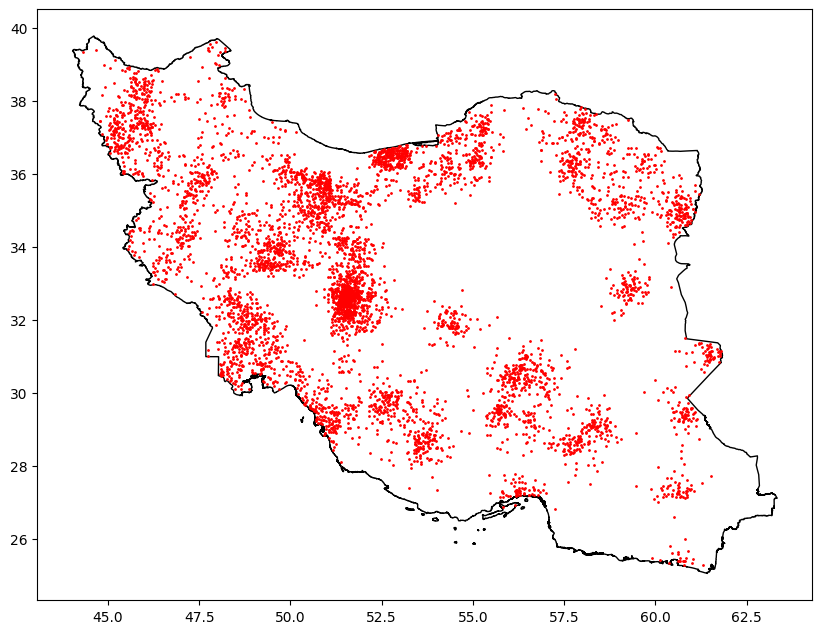

In [5]:
plot_points(iran_shapefile, gdf_coords_iran, marker_size=1)

## class proportion

In [6]:
lcs, lcs_unique = read_labels(gdf_coords_iran, fdir_iran_data)

  0%|          | 0/5480 [00:00<?, ?it/s]

100%|██████████| 5480/5480 [03:26<00:00, 26.60it/s]


shape of lcs: (264, 264, 5480)
unique values in lcs: [ 1  2  3  4  5  6  7  8  9 10 11 12 13]


In [7]:
lcs_unique = np.unique(lcs)
lcs_proportions = get_label_proportions(lcs, lcs_unique)

Proportion of 001: 4.59%
Proportion of 002: 0.58%
Proportion of 003: 6.61%
Proportion of 004: 16.00%
Proportion of 005: 1.58%
Proportion of 006: 0.64%
Proportion of 007: 8.16%
Proportion of 008: 1.82%
Proportion of 009: 11.01%
Proportion of 010: 3.34%
Proportion of 011: 3.17%
Proportion of 012: 30.68%
Proportion of 013: 11.81%


## show images

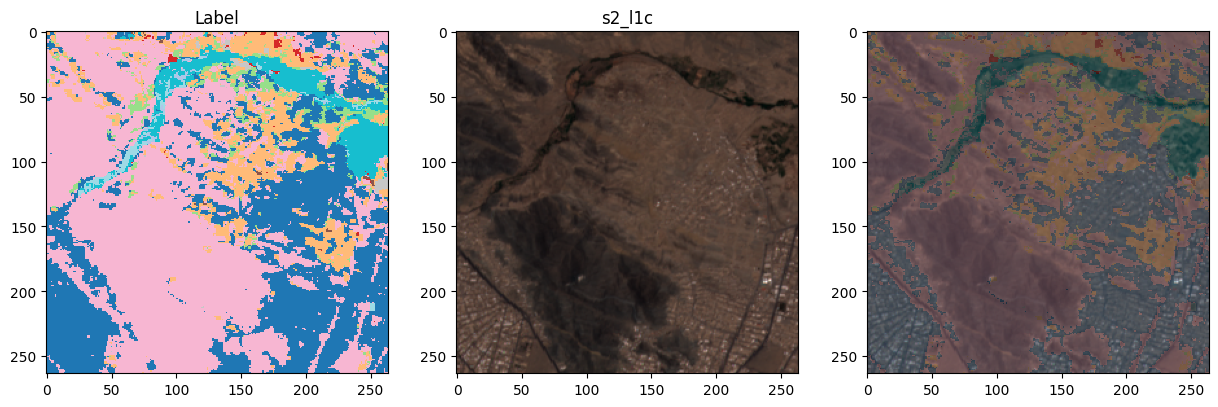

In [8]:
i = 0
ind = gdf_coords_iran.id.iloc[i]
show_image_example(fdir_iran_data, ind, img_names=['s2_l1c'], img_bands=[3,2,1], lbl_name='lc', alpha=0.25)

## shuffle the indexes and create lmdb

In [11]:
fp_new_csv_iran = os.path.join(fd_used_csv, 'center_coords_iran.csv')
# shuffle indexes
shuffled_indexes = np.random.permutation(len(gdf_coords_iran))
new_gdf_coords_iran = gdf_coords_iran.iloc[shuffled_indexes]
new_gdf_coords_iran.reset_index(drop=True, inplace=True)
new_gdf_coords_iran.loc[:, ['id', 'longitude', 'latitude', 's2_imageid', 'coords', 'n_nodata']].to_csv(fp_new_csv_iran, index=False)
new_gdf_coords_iran

,id,s2_imageid,longitude,latitude,coords,init_image_shape,n_nodata,geometry
0,73995,20170805T065621_20170805T070032_T40SCF,55.339169,36.169703,"[[55.32735434506369, 36.181581873055976], [55....","(264, 264)",0,POINT (55.33917 36.16970)
1,47701,20170823T071259_20170823T071728_T40SBE,54.512225,35.987977,"[[54.500357182011825, 35.999855083055984], [54...","(264, 264)",0,POINT (54.51223 35.98798)
2,124329,20170707T072309_20170707T072929_T39RWP,51.323159,30.719881,"[[51.311337847057615, 30.731670288161776], [51...","(264, 264)",0,POINT (51.32316 30.71988)
3,117695,20170804T064019_20170804T064458_T41RLQ,61.490842,31.353852,"[[61.479019878836205, 31.365730703055977], [61...","(264, 265)",0,POINT (61.49084 31.35385)
4,57630,20170712T071621_20170712T072717_T39SUR,49.717145,31.655166,"[[49.70536172569512, 31.66704468305598], [49.7...","(264, 264)",0,POINT (49.71715 31.65517)
...,...,...,...,...,...,...,...,...
5475,77213,20170717T071619_20170717T072352_T39SVU,50.550117,34.966339,"[[50.53825247410142, 34.978217713055976], [50....","(264, 264)",0,POINT (50.55012 34.96634)
5476,213191,20170612T072301_20170612T072304_T39SWS,51.086648,33.170691,"[[51.07481092253965, 33.18257000305597], [51.0...","(264, 264)",0,POINT (51.08665 33.17069)
5477,75944,20170702T071731_20170702T072955_T39SWR,51.375364,31.885453,"[[51.363551029409855, 31.897331513055974], [51...","(264, 264)",0,POINT (51.37536 31.88545)
5478,123015,20170702T071731_20170702T072955_T39SVS,50.340384,33.227818,"[[50.32853907739984, 33.23969648305598], [50.3...","(264, 264)",0,POINT (50.34038 33.22782)


In [13]:
fp_lmdb = os.path.join(fd_lmdb, 'iran.lmdb')
gsize = 10
img_names = ['s2_l1c', 'lc']

create_lmdb(fdir_iran_data, fp_lmdb, gsize, new_gdf_coords_iran.id, img_names)

  0%|          | 0/5480 [00:00<?, ?it/s]

100%|██████████| 5480/5480 [03:48<00:00, 23.98it/s]


Read data into /p/scratch/hai_dm4eo/liu_ch/data/WeakFT/weak_lmdbs/iran.lmdb|Elapsed time: 0:03:54


124329 124329 (13, 264, 264) (264, 264) 10961 5480 ['s2_l1c', 'lc']


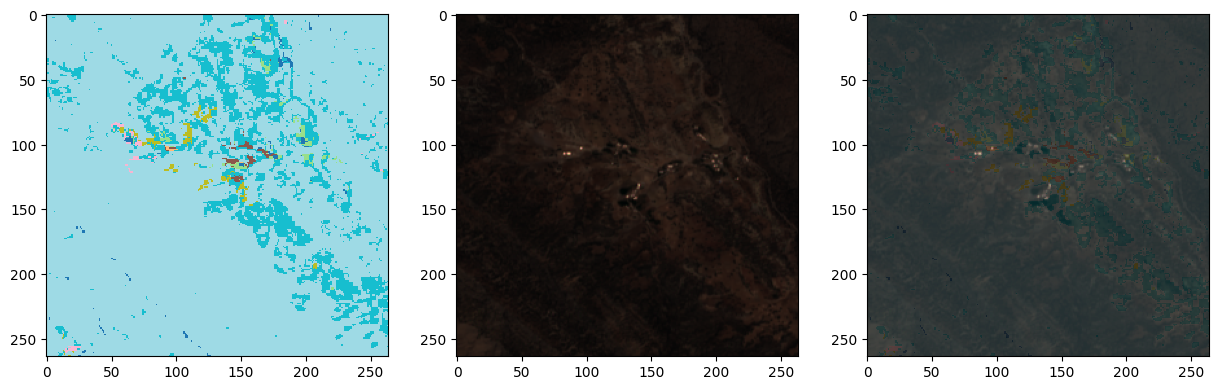

In [14]:
# check saved lmdb file
i = 2
env = lmdb.open(fp_lmdb, max_readers=1, readonly=True, lock=False, readahead=False, meminit=False)
with env.begin(write=False) as txn:
    n_items = txn.stat()['entries']
    keys = pickle.loads(txn.get('keys'.encode()))
    img_obj = pickle.loads(txn.get((f'{i}_s2_l1c').encode()))
    lbl_obj = pickle.loads(txn.get((f'{i}_lc').encode()))
    img = np.frombuffer(img_obj[0], dtype=np.uint16).reshape(img_obj[1])
    lbl = np.frombuffer(lbl_obj[0], dtype=np.uint8).reshape(lbl_obj[1]).squeeze()
    print(img_obj[-1], lbl_obj[-1], img.shape, lbl.shape, n_items, int((n_items-1)//2), keys)
    plt.figure(figsize=(15, 5))
    plt.subplot(131)
    plt.imshow(lbl, cmap='tab20', interpolation='none')
    plt.subplot(132)
    im = img[[3,2,1]].transpose(1,2,0)
    im = (im - np.min(im)) / (np.max(im) - np.min(im))

    # # ssl4eo-s12_0k_251k_s2c_norm.lmdb (used by NS_Pr project)
    # im = []
    # for i in [3,2,1]:
    #     im_ = img[i].astype(np.float32)
    #     vmin = S2C_MEAN[i] - 2*S2C_STD[i]
    #     vmax = S2C_MEAN[i] + 2*S2C_STD[i]
    #     im_ = ((im_-vmin) / (vmax-vmin))*255
    #     im_ = im_.astype(np.uint8)
    #     im.append(im_)
    # im = np.stack(im, axis=2)
    
    # # ssl4eo-s12_0k_251k.lmdb
    # im = img[[3,2,1]].transpose(1,2,0)
    # im = im/10000 # (im - np.min(im)) / (np.max(im) - np.min(im))

    plt.imshow(im)
    plt.subplot(133)
    plt.imshow(im)
    plt.imshow(lbl, cmap='tab20', alpha=0.2, interpolation='none')

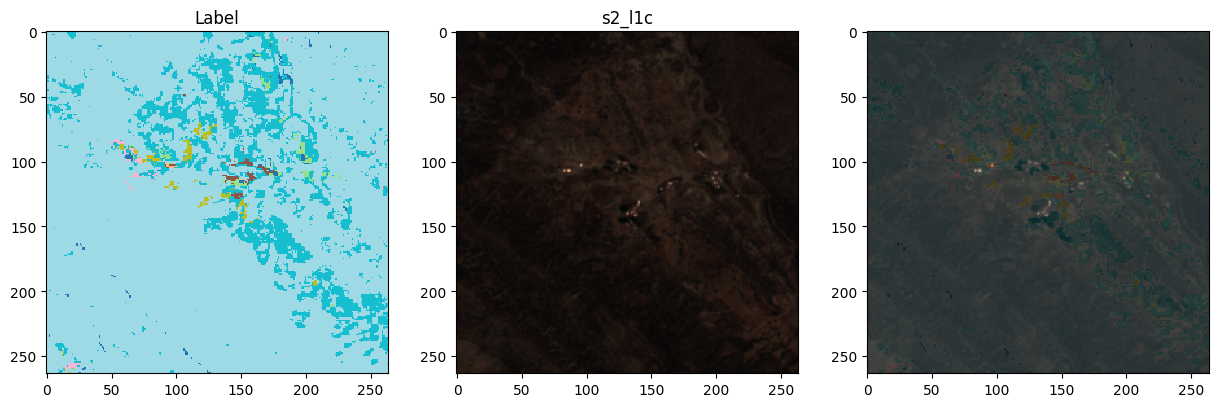

In [15]:
show_image_example(fdir_iran_data, img_obj[-1], img_names=['s2_l1c'], img_bands=[3,2,1], lbl_name='lc', alpha=0.2)

In [3]:
fp_lmdb = os.path.join(fd_lmdb, 'iran.lmdb')
labels = []
env = lmdb.open(fp_lmdb, max_readers=1, readonly=True, lock=False, readahead=False, meminit=False)
with env.begin(write=False) as txn:
    n_items = txn.stat()['entries']
    keys = pickle.loads(txn.get('keys'.encode()))
    for i in range(int((n_items-1)//2)):
        lbl_obj = pickle.loads(txn.get((f'{i}_lc').encode()))
        lbl = np.frombuffer(lbl_obj[0], dtype=np.uint8).reshape(lbl_obj[1]).squeeze()
        labels.append(lbl)
labels = np.dstack(labels)
n_items, keys, labels.shape, np.unique(labels)

(10961,
 ['s2_l1c', 'lc'],
 (264, 264, 5480),
 array([ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13], dtype=uint8))

# WorldCover

In [7]:
# shapefile
world_shapefile = gpd.read_file('world_shp/world-administrative-boundaries.shp')
# data points
fdir_wc_data = {}
fdir_wcv1 = os.path.join(fd_pdata,'worldcover_v100')
fdir_wcv1_data = os.path.join(fdir_wcv1, 'data')
fdir_wcv1_csv  = os.path.join(fdir_wcv1, 'Downloaded_file_info_lc.csv')
points_wcv1 = pd.read_csv(fdir_wcv1_csv, header=0)
fdir_wc_data['worldcover_v100'] = fdir_wcv1_data
fdir_wcv2 = os.path.join(fd_pdata,'worldcover_v200')
fdir_wcv2_data = os.path.join(fdir_wcv2, 'data')
fdir_wcv2_csv  = os.path.join(fdir_wcv2, 'Downloaded_file_info_lc.csv')
points_wcv2 = pd.read_csv(fdir_wcv2_csv, header=0)
fdir_wc_data['worldcover_v200'] = fdir_wcv2_data
# Convert the DataFrame to a GeoDataFrame
dfs = {}
dfs['worldcover_v100'] = gpd.GeoDataFrame(points_wcv1, geometry=gpd.points_from_xy(points_wcv1.longitude, points_wcv1.latitude))
dfs['worldcover_v200'] = gpd.GeoDataFrame(points_wcv2, geometry=gpd.points_from_xy(points_wcv2.longitude, points_wcv2.latitude))
for k in dfs:
    print(f'{k}: {len(dfs[k])}')

worldcover_v100: 45922
worldcover_v200: 45334


In [12]:
dfs[k]

,id,s2_imageid,longitude,latitude,coords,init_image_shape,n_nodata,geometry
0,201414,20210605T024549_20210605T025350_T50SPG,118.437879,37.227436,"[[118.42603798570684, 37.23922478816119], [118...","(264, 264)",0,POINT (118.43788 37.22744)
1,80719,20210605T024549_20210605T025350_T51SUB,120.962813,37.125954,"[[120.95099692304082, 37.13783224305598], [120...","(264, 264)",0,POINT (120.96281 37.12595)
2,68010,20210629T100031_20210629T100408_T33TUL,13.700810,45.415281,"[[13.689033813258519, 45.427159533055985], [13...","(264, 264)",0,POINT (13.70081 45.41528)
3,11473,20210612T173909_20210612T174342_T13TDE,-105.074348,39.762541,"[[-105.08617301379829, 39.77441925305598], [-1...","(264, 264)",0,POINT (-105.07435 39.76254)
4,92122,20210621T095029_20210621T095030_T34UCB,18.709153,50.568060,"[[18.69731904982619, 50.57984898815956], [18.7...","(264, 264)",0,POINT (18.70915 50.56806)
...,...,...,...,...,...,...,...,...
45329,129436,20210208T132229_20210208T132522_T22JET,-50.031096,-24.589547,"[[-50.04288983867552, -24.577668536944017], [-...","(264, 264)",0,POINT (-50.03110 -24.58955)
45330,221207,20210308T141739_20210308T142711_T20JLT,-64.817490,-24.790292,"[[-64.82930243194957, -24.778413776944017], [-...","(264, 264)",0,POINT (-64.81749 -24.79029)
45331,139337,20210702T082601_20210702T082955_T36SWD,33.671878,35.113503,"[[33.660074251779655, 35.12538120305598], [33....","(264, 264)",0,POINT (33.67188 35.11350)
45332,243109,20210622T092029_20210622T092028_T34UGV,23.983895,48.994643,"[[23.97211340600506, 49.00643184815981], [23.9...","(264, 264)",0,POINT (23.98390 48.99464)


## plot the overlap points - 44087

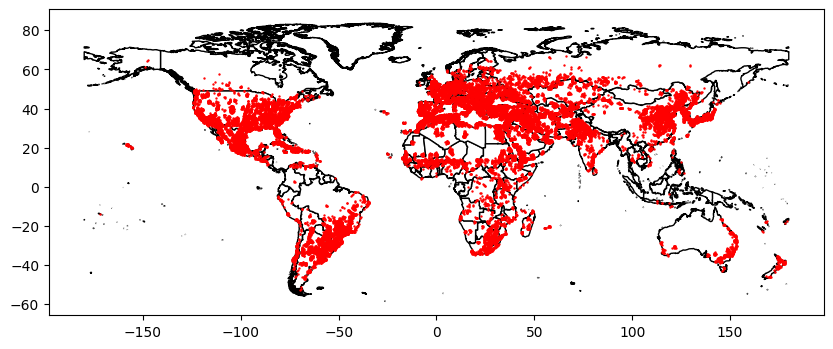

44086

In [13]:
d1 = dfs['worldcover_v100'].id
d2 = dfs['worldcover_v200'].id
overlap = d1[d1.isin(d2)]
gdf_overlap_points = dfs['worldcover_v100'].iloc[overlap.index]
fig, ax = plt.subplots(figsize=(10, 10))
world_shapefile.plot(ax=ax, color='white', edgecolor='black')
gdf_overlap_points.plot(ax=ax, color='red', markersize=.5)
plt.show()
len(gdf_overlap_points)

In [14]:
gdf_overlap_points

,id,s2_imageid,longitude,latitude,coords,init_image_shape,n_nodata,geometry
0,201414,20200603T025549_20200603T030230_T50SPG,118.437879,37.227436,"[[118.42603798570684, 37.23922478816119], [118...","(264, 264)",0,POINT (118.43788 37.22744)
1,80719,20200725T024551_20200725T024551_T51SUB,120.962813,37.125954,"[[120.95099692304082, 37.13783224305598], [120...","(264, 264)",0,POINT (120.96281 37.12595)
2,68010,20200808T100029_20200808T100254_T33TUL,13.700810,45.415281,"[[13.689033813258519, 45.427159533055985], [13...","(264, 264)",0,POINT (13.70081 45.41528)
3,11473,20200612T173911_20200612T174503_T13TDE,-105.074348,39.762541,"[[-105.08617301379829, 39.77441925305598], [-1...","(264, 264)",0,POINT (-105.07435 39.76254)
4,92122,20200701T095031_20200701T095501_T33UYS,18.709153,50.568060,"[[18.69731904982619, 50.57984898815956], [18.7...","(264, 264)",0,POINT (18.70915 50.56806)
...,...,...,...,...,...,...,...,...
45917,129436,20200310T132231_20200310T132229_T22JET,-50.031096,-24.589547,"[[-50.04288983867552, -24.577668536944017], [-...","(264, 264)",0,POINT (-50.03110 -24.58955)
45918,221207,20200303T141729_20200303T142734_T20JLT,-64.817490,-24.790292,"[[-64.82930243194957, -24.778413776944017], [-...","(264, 264)",0,POINT (-64.81749 -24.79029)
45919,139337,20200612T082609_20200612T083943_T36SWD,33.671878,35.113503,"[[33.660074251779655, 35.12538120305598], [33....","(264, 264)",0,POINT (33.67188 35.11350)
45920,243109,20200806T092029_20200806T092031_T34UGV,23.983895,48.994643,"[[23.97211340600506, 49.00643184815981], [23.9...","(264, 264)",0,POINT (23.98390 48.99464)


## shuffle the indexes and create lmdb

In [15]:
fp_new_csv_wv = os.path.join(fd_used_csv, 'center_coords_overlap_worldcover.csv')
shuffled_indexes = np.random.permutation(len(gdf_overlap_points))
new_gdf_overlap_points = gdf_overlap_points.iloc[shuffled_indexes]
new_gdf_overlap_points.reset_index(drop=True, inplace=True)
overlap_points = new_gdf_overlap_points.loc[:, ['id', 'longitude', 'latitude', 's2_imageid', 'coords']]
overlap_points.to_csv(fp_new_csv_wv, index=False)
new_gdf_overlap_points

,id,s2_imageid,longitude,latitude,coords,init_image_shape,n_nodata,geometry
0,124493,20200201T075039_20200201T080648_T35JPM,28.983212,-25.940940,"[[28.971364467494205, -25.92915129183438], [28...","(264, 264)",0,POINT (28.98321 -25.94094)
1,86593,20200801T155911_20200801T160644_T17RNM,-80.557941,28.380582,"[[-80.56980668791998, 28.39246032305598], [-80...","(264, 264)",0,POINT (-80.55794 28.38058)
2,62830,20200601T103629_20200601T104439_T32UME,8.442448,53.575770,"[[8.430591107569478, 53.58764835305599], [8.45...","(264, 265)",0,POINT (8.44245 53.57577)
3,156193,20200829T074619_20200829T075215_T38SNG,45.258772,37.358621,"[[45.24690963021549, 37.370499613055976], [45....","(264, 264)",0,POINT (45.25877 37.35862)
4,147420,20200720T074619_20200720T075210_T38TNL,45.423294,41.076761,"[[45.41151187683169, 41.088639013055975], [45....","(264, 264)",0,POINT (45.42329 41.07676)
...,...,...,...,...,...,...,...,...
44081,151634,20200210T221559_20200210T221558_T60HVD,176.486940,-37.227708,"[[176.47509796206086, -37.21591849183343], [17...","(264, 264)",0,POINT (176.48694 -37.22771)
44082,96217,20200602T082609_20200602T084159_T36RVQ,32.225903,26.351276,"[[32.214098631812405, 26.363064718162125], [32...","(264, 264)",0,POINT (32.22590 26.35128)
44083,32780,20200305T132229_20200305T132230_T22KGA,-48.767269,-21.934867,"[[-48.77907774421291, -21.92307786183468], [-4...","(264, 264)",0,POINT (-48.76727 -21.93487)
44084,99444,20200608T102559_20200608T104609_T30QZD,-0.162797,17.044425,"[[-0.17458358412529396, 17.056303923055978], [...","(264, 264)",0,POINT (-0.16280 17.04443)


In [3]:
fp_new_csv_wv = os.path.join(fd_used_csv, 'center_coords_overlap_worldcover.csv')
new_gdf_overlap_points = pd.read_csv(fp_new_csv_wv)
new_gdf_overlap_points

,id,longitude,latitude,s2_imageid,coords
0,124493,28.983212,-25.940940,20200201T075039_20200201T080648_T35JPM,"[[28.971364467494205, -25.92915129183438], [28..."
1,86593,-80.557941,28.380582,20200801T155911_20200801T160644_T17RNM,"[[-80.56980668791998, 28.39246032305598], [-80..."
2,62830,8.442448,53.575770,20200601T103629_20200601T104439_T32UME,"[[8.430591107569478, 53.58764835305599], [8.45..."
3,156193,45.258772,37.358621,20200829T074619_20200829T075215_T38SNG,"[[45.24690963021549, 37.370499613055976], [45...."
4,147420,45.423294,41.076761,20200720T074619_20200720T075210_T38TNL,"[[45.41151187683169, 41.088639013055975], [45...."
...,...,...,...,...,...
44081,151634,176.486940,-37.227708,20200210T221559_20200210T221558_T60HVD,"[[176.47509796206086, -37.21591849183343], [17..."
44082,96217,32.225903,26.351276,20200602T082609_20200602T084159_T36RVQ,"[[32.214098631812405, 26.363064718162125], [32..."
44083,32780,-48.767269,-21.934867,20200305T132229_20200305T132230_T22KGA,"[[-48.77907774421291, -21.92307786183468], [-4..."
44084,99444,-0.162797,17.044425,20200608T102559_20200608T104609_T30QZD,"[[-0.17458358412529396, 17.056303923055978], [..."


In [8]:
gsize = 147
img_names = ['s2_l1c', 's2_l2a', 'lc']

for v in [100, 200]:
    fp_lmdb = os.path.join(fd_lmdb, f'worldcover_v{v}.lmdb')
    create_lmdb(fdir_wc_data[f'worldcover_v{v}'], fp_lmdb, gsize, new_gdf_overlap_points.id, img_names)

  0%|          | 2/44086 [00:00<1:45:34,  6.96it/s]

100%|██████████| 44086/44086 [1:02:05<00:00, 11.83it/s]


Read data into /p/scratch/hai_ws4eo/liu_ch/data/WeakFT/weak_lmdbs/worldcover_v100.lmdb|Elapsed time: 1:03:22


100%|██████████| 44086/44086 [1:16:07<00:00,  9.65it/s]


Read data into /p/scratch/hai_ws4eo/liu_ch/data/WeakFT/weak_lmdbs/worldcover_v200.lmdb|Elapsed time: 1:17:24


62830 62830 (13, 264, 264) (264, 265) 132259 66129 ['s2_l1c', 's2_l2a', 'lc']


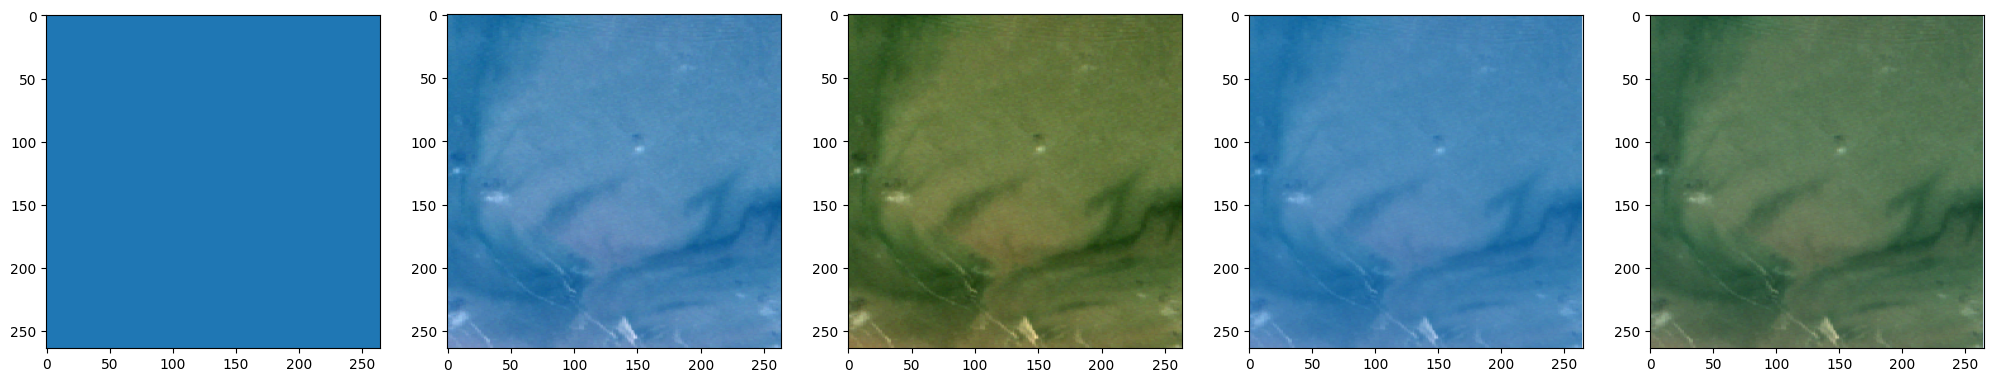

In [17]:
# check saved lmdb file
i = 2
v = 200
fp_lmdb = os.path.join(fd_lmdb, f'worldcover_v{v}.lmdb')
env = lmdb.open(fp_lmdb, max_readers=1, readonly=True, lock=False, readahead=False, meminit=False)
with env.begin(write=False) as txn:
    n_items = txn.stat()['entries']
    keys = pickle.loads(txn.get('keys'.encode()))
    img_obj = pickle.loads(txn.get((f'{i}_s2_l1c').encode()))
    imga_obj = pickle.loads(txn.get((f'{i}_s2_l2a').encode()))
    lbl_obj = pickle.loads(txn.get((f'{i}_lc').encode()))
    img = np.frombuffer(img_obj[0], dtype=np.uint16).reshape(img_obj[1])
    imga = np.frombuffer(imga_obj[0], dtype=np.uint16).reshape(imga_obj[1])
    lbl = np.frombuffer(lbl_obj[0], dtype=np.uint8).reshape(lbl_obj[1]).squeeze()
    print(img_obj[-1], lbl_obj[-1], img.shape, lbl.shape, n_items, int((n_items-1)//2), keys)
    plt.figure(figsize=(25, 5))
    plt.subplot(151)
    plt.imshow(lbl, cmap='tab20', interpolation='none')
    plt.subplot(152)
    im = img[[3,2,1]].transpose(1,2,0)
    im = (im - np.min(im)) / (np.max(im) - np.min(im))
    plt.imshow(im)
    plt.subplot(153)
    ima = imga[[3,2,1]].transpose(1,2,0)
    ima = (ima - np.min(ima)) / (np.max(ima) - np.min(ima))
    plt.imshow(ima)
    plt.subplot(154)
    plt.imshow(im)
    plt.imshow(lbl, cmap='tab20', alpha=0.2, interpolation='none')
    plt.subplot(155)
    plt.imshow(ima)
    plt.imshow(lbl, cmap='tab20', alpha=0.2, interpolation='none')

In [18]:
(n_items-1)/3

44086.0

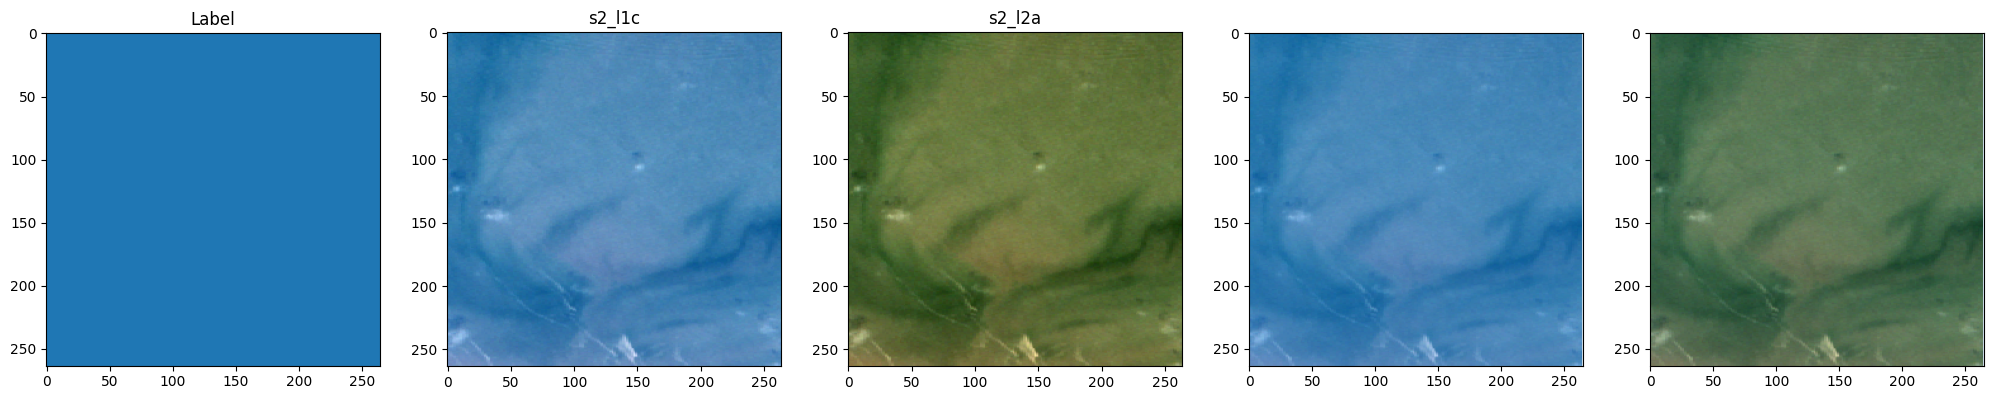

In [19]:
show_image_example(fdir_wc_data[f'worldcover_v{v}'], img_obj[-1], img_names=['s2_l1c', 's2_l2a'], img_bands=[3,2,1], lbl_name='lc', alpha=0.2)

## class proportions

In [13]:
for v in [100, 200]:
    fp_lmdb = os.path.join(fd_lmdb, f'worldcover_v{v}.lmdb')
    labels = []
    env = lmdb.open(fp_lmdb, max_readers=1, readonly=True, lock=False, readahead=False, meminit=False)
    with env.begin(write=False) as txn:
        n_items = txn.stat()['entries']
        keys = pickle.loads(txn.get('keys'.encode()))
        for i in range(int((n_items-1)//3)):
            lbl_obj = pickle.loads(txn.get((f'{i}_lc').encode()))
            lbl = np.frombuffer(lbl_obj[0], dtype=np.uint8).reshape(lbl_obj[1]).squeeze()
            labels.append(lbl)
    labels = np.dstack(labels)
    uni_vs = np.unique(labels)
    print(f'v{v}', n_items, keys, labels.shape, uni_vs)
    for uni_v in uni_vs:
        na = np.sum(labels==uni_v)
        print(f'v{v} {uni_v}: {na}, {na/labels.size*100:.2f}%')

v100 132259 ['s2_l1c', 's2_l2a', 'lc'] (264, 264, 44086) [ 10  20  30  40  50  60  70  80  90  95 100]
v100 10: 638668598, 20.79%
v100 20: 216032085, 7.03%
v100 30: 606015485, 19.72%
v100 40: 742009258, 24.15%
v100 50: 138763294, 4.52%
v100 60: 398807687, 12.98%
v100 70: 99225, 0.00%
v100 80: 314401592, 10.23%
v100 90: 16202326, 0.53%
v100 95: 1402079, 0.05%
v100 100: 216227, 0.01%
v200 132259 ['s2_l1c', 's2_l2a', 'lc'] (264, 264, 44086) [ 10  20  30  40  50  60  70  80  90  95 100]
v200 10: 686315701, 22.34%
v200 20: 198665229, 6.47%
v200 30: 630746085, 20.53%
v200 40: 734954678, 23.92%
v200 50: 152008727, 4.95%
v200 60: 336827437, 10.96%
v200 70: 107139, 0.00%
v200 80: 314841684, 10.25%
v200 90: 16868763, 0.55%
v200 95: 1211999, 0.04%
v200 100: 70414, 0.00%


In [3]:
lbl = labels.copy()
lbl[lbl>90] = lbl[lbl>90]+10
lbl = np.floor(lbl/10).astype(np.uint8)
lbl = lbl - 1
np.unique(lbl)

array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10], dtype=uint8)

In [4]:
lbl_obj[-1]

6659

# GHSL

In [7]:
# shapefile
world_shapefile = gpd.read_file('world_shp/world-administrative-boundaries.shp')
# data points
fdir_ghsl_data = {}
fdir_ghsl = os.path.join(fd_pdata,'ghsl_s2c_only')
fdir_ghsl_data = os.path.join(fdir_ghsl, 'data')
fdir_ghsl_csv  = os.path.join(fdir_ghsl, 'Downloaded_file_info_lc.csv')
points_ghsl = pd.read_csv(fdir_ghsl_csv, header=0)

# Convert the DataFrame to a GeoDataFrame
df_ghsl = gpd.GeoDataFrame(points_ghsl, geometry=gpd.points_from_xy(points_ghsl.longitude, points_ghsl.latitude))
len(df_ghsl)

33687

In [10]:
df_ghsl

,id,s2_imageid,longitude,latitude,coords,init_image_shape,n_nodata,geometry
0,19837,20180619T112111_20180619T112602_T29SNC,-8.652062,38.723866,"[[-8.663852080535449, 38.73565479816104], [-8....","(264, 264)",64568,POINT (-8.65206 38.72387)
1,239329,20180615T072619_20180615T073843_T38QPM,46.342296,24.050558,"[[46.33046783062149, 24.06243646305598], [46.3...","(264, 264)",69517,POINT (46.34230 24.05056)
2,211881,20180603T082559_20180603T082852_T37TDL,37.977172,45.399942,"[[37.96532311744947, 45.41173073816027], [37.9...","(264, 264)",66515,POINT (37.97717 45.39994)
3,219067,20180609T175911_20180609T181449_T12SVC,-111.641008,33.572058,"[[-111.65281752385773, 33.58393612305599], [-1...","(264, 264)",69680,POINT (-111.64101 33.57206)
4,188380,20180812T082559_20180812T083913_T36RUU,31.589965,30.110752,"[[31.57814048083893, 30.122630353055985], [31....","(264, 264)",52013,POINT (31.58997 30.11075)
...,...,...,...,...,...,...,...,...
33682,82065,20180602T053639_20180602T054134_T43REQ,76.107798,30.826576,"[[76.09595763892311, 30.83836499816177], [76.1...","(264, 264)",63240,POINT (76.10780 30.82658)
33683,3017,20180724T103021_20180724T103551_T32UNU,9.489438,48.597244,"[[9.477630753552754, 48.60903304815985], [9.50...","(264, 265)",55574,POINT (9.48944 48.59724)
33684,145751,20180109T135101_20180109T135310_T20HPE,-60.938235,-37.095894,"[[-60.95004724475548, -37.084015016944015], [-...","(264, 264)",69674,POINT (-60.93823 -37.09589)
33685,140090,20180603T055641_20180603T060211_T42RXS,70.054975,28.558939,"[[70.0431732818212, 28.570817503055977], [70.0...","(264, 264)",66427,POINT (70.05497 28.55894)


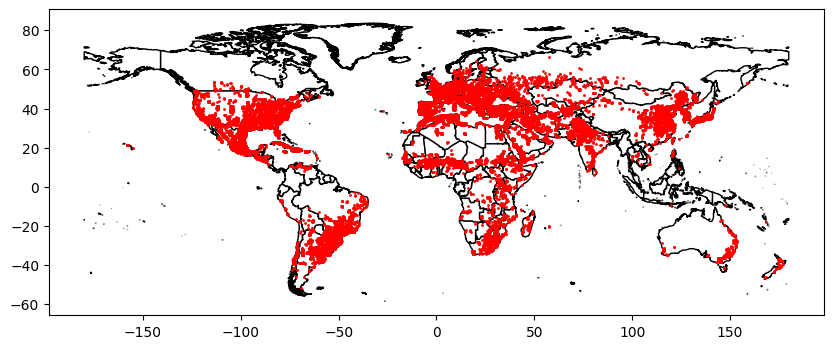

In [8]:
plot_points(world_shapefile, df_ghsl, marker_size=1)

In [11]:
fp_new_csv_ghsl = os.path.join(fd_used_csv, 'center_coords_ghsl.csv')
# shuffle indexes
shuffled_indexes = np.random.permutation(len(df_ghsl))
new_gdf_coords_ghsl = df_ghsl.iloc[shuffled_indexes]
new_gdf_coords_ghsl.reset_index(drop=True, inplace=True)
new_gdf_coords_ghsl.loc[:, ['id', 'longitude', 'latitude', 's2_imageid', 'coords', 'n_nodata']].to_csv(fp_new_csv_ghsl, index=False)
new_gdf_coords_ghsl

,id,s2_imageid,longitude,latitude,coords,init_image_shape,n_nodata,geometry
0,228516,20180618T082601_20180618T083922_T36RUS,31.019651,28.384312,"[[31.00778422471325, 28.39619045305598], [31.0...","(264, 264)",69543,POINT (31.01965 28.38431)
1,158783,20180601T024539_20180601T025121_T51TVE,122.383220,40.594927,"[[122.37137669850878, 40.60680537305597], [122...","(264, 265)",58176,POINT (122.38322 40.59493)
2,130371,20180601T015651_20180601T015653_T53SKU,132.446179,34.619170,"[[132.43437191533536, 34.63095899816143], [132...","(264, 265)",58902,POINT (132.44618 34.61917)
3,221721,20180614T184921_20180614T190114_T10SFG,-121.781165,37.301637,"[[-121.79301818670521, 37.31342648816118], [-1...","(264, 264)",19232,POINT (-121.78117 37.30164)
4,33114,20180624T103021_20180624T103503_T31SEA,3.602300,36.169670,"[[3.5904860980259237, 36.18145965816128], [3.6...","(264, 264)",68869,POINT (3.60230 36.16967)
...,...,...,...,...,...,...,...,...
33682,114678,20180630T154911_20180630T155933_T18TVM,-75.943020,41.846010,"[[-75.95488648452366, 41.85788863305598], [-75...","(264, 264)",68340,POINT (-75.94302 41.84601)
33683,229962,20180614T075609_20180614T080541_T38TMP,44.478043,43.299910,"[[44.46624418978305, 43.31178842305598], [44.4...","(264, 265)",69170,POINT (44.47804 43.29991)
33684,250277,20180802T023551_20180802T024121_T51TYK,126.179993,44.412721,"[[126.1681559424684, 44.42451007816041], [126....","(264, 264)",68531,POINT (126.17999 44.41272)
33685,202302,20180814T090549_20180814T091348_T35TNN,27.100437,47.118472,"[[27.08866538380592, 47.13035045305599], [27.1...","(264, 264)",69631,POINT (27.10044 47.11847)


In [13]:
# read all the label masks
lbls = []
for i in tqdm(range(len(new_gdf_coords_ghsl)), total=len(new_gdf_coords_ghsl)):
    ind = new_gdf_coords_ghsl.id.iloc[i]
    fp = os.path.join(fdir_ghsl_data, f'{ind:07d}', 'bc.tif')
    with rasterio.open(fp, 'r') as src:
        lbl = src.read().squeeze()
        lbls.append(lbl)
lbls = np.dstack(lbls)
tmp = lbls>10
n_data = np.sum(tmp, axis=(0,1))
np.sum(n_data==0)

100%|██████████| 33687/33687 [17:54<00:00, 31.36it/s]


50

In [39]:
np.sum(n_data>=264*10)

9283

In [44]:
select_gdf_coords_ghsl = new_gdf_coords_ghsl.iloc[n_data>=264*10]
fp_new_csv_ghsl_select = os.path.join(fd_used_csv, 'center_coords_ghsl_select.csv')
select_gdf_coords_ghsl.to_csv(fp_new_csv_ghsl_select, index=False)
select_gdf_coords_ghsl

,id,s2_imageid,longitude,latitude,coords,init_image_shape,n_nodata,geometry
1,158783,20180601T024539_20180601T025121_T51TVE,122.383220,40.594927,"[[122.37137669850878, 40.60680537305597], [122...","(264, 265)",58176,POINT (122.38322 40.59493)
2,130371,20180601T015651_20180601T015653_T53SKU,132.446179,34.619170,"[[132.43437191533536, 34.63095899816143], [132...","(264, 265)",58902,POINT (132.44618 34.61917)
3,221721,20180614T184921_20180614T190114_T10SFG,-121.781165,37.301637,"[[-121.79301818670521, 37.31342648816118], [-1...","(264, 264)",19232,POINT (-121.78117 37.30164)
5,97773,20180604T161859_20180604T162407_T16SGB,-84.552390,33.326562,"[[-84.56424874720683, 33.33844014305598], [-84...","(264, 264)",59387,POINT (-84.55239 33.32656)
18,243699,20180605T031541_20180605T032126_T49SDU,110.944277,34.556051,"[[110.93247877999602, 34.56792997305598], [110...","(264, 264)",58135,POINT (110.94428 34.55605)
...,...,...,...,...,...,...,...,...
33662,83309,20180612T030541_20180612T031743_T50SLE,115.449547,35.586423,"[[115.43774717644172, 35.598301833055984], [11...","(264, 264)",63463,POINT (115.44955 35.58642)
33666,95534,20180624T075609_20180624T081644_T36NWG,33.842213,1.063119,"[[33.83042889156271, 1.0749979470559792], [33....","(264, 264)",60633,POINT (33.84221 1.06312)
33668,242009,20180601T183931_20180601T185345_T10SFG,-121.007849,37.324196,"[[-121.01962536266882, 37.33598518816116], [-1...","(264, 264)",48850,POINT (-121.00785 37.32420)
33671,39519,20180611T160829_20180611T160958_T17TPJ,-79.379784,43.746191,"[[-79.3916175711407, 43.75806972305599], [-79....","(264, 264)",19681,POINT (-79.37978 43.74619)


In [43]:
lbls_sel = []
for i in tqdm(range(len(select_gdf_coords_ghsl)), total=len(select_gdf_coords_ghsl)):
    ind = select_gdf_coords_ghsl.id.iloc[i]
    fp = os.path.join(fdir_ghsl_data, f'{ind:07d}', 'bc.tif')
    with rasterio.open(fp, 'r') as src:
        lbl = src.read().squeeze()
        lbls_sel.append(lbl)
lbls_sel = np.dstack(lbls_sel)
tmp = lbls_sel>10
n_data_sel = np.sum(tmp, axis=(0,1))
np.sum(n_data_sel<264*10)

100%|██████████| 9283/9283 [00:11<00:00, 781.43it/s]


0

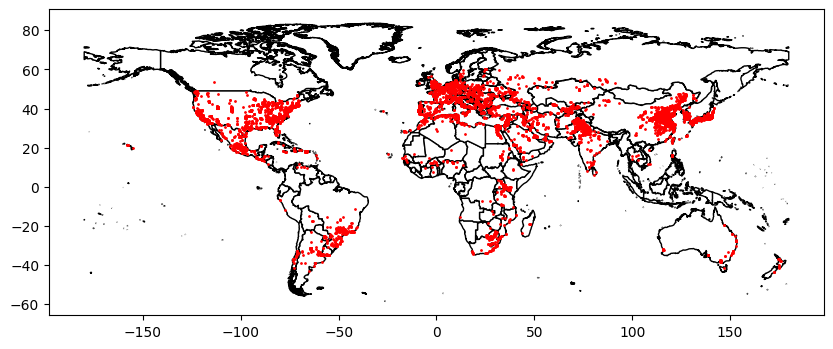

In [42]:
plot_points(world_shapefile, select_gdf_coords_ghsl, marker_size=1)

In [48]:
fp_lmdb = os.path.join(fd_lmdb, 'ghsl_select.lmdb')
gsize = 17
img_names = ['s2_l1c', 'bc']

create_lmdb(fdir_ghsl_data, fp_lmdb, gsize, select_gdf_coords_ghsl.id, img_names)

100%|██████████| 9283/9283 [07:11<00:00, 21.54it/s]


Read data into /p/scratch/hai_ws4eo/liu_ch/data/WeakFT/weak_lmdbs/ghsl_select.lmdb|Elapsed time: 0:07:19


# NLCD

In [28]:
# create continental US shapefile
world_shapefile = gpd.read_file('/p/project1/hai_ws4eo/liu_ch/Weak_FT/segment-anything-2/data_downloading/world_shp/world-administrative-boundaries.shp')
# Create an empty list to store individual polygons
us_shapefile = world_shapefile[world_shapefile['name'] == 'United States of America']
split_polygons = []
min_longitude, max_longitude = -128, -50

# Iterate over each geometry in the GeoDataFrame
for geom in us_shapefile.geometry:
    if isinstance(geom, MultiPolygon):
        # If the geometry is a MultiPolygon, iterate over individual polygons
        for poly in geom.geoms:
            # Check the bounds of the polygon (min_x, min_y, max_x, max_y)
            if poly.bounds[0] >= min_longitude and poly.bounds[2] <= max_longitude:
                split_polygons.append(poly)
    else:
        # If the geometry is already a Polygon, check its bounds
        if geom.bounds[0] >= min_longitude and geom.bounds[2] <= max_longitude:
            split_polygons.append(geom)

# Create a new GeoDataFrame with the split polygons
split_gdf = gpd.GeoDataFrame(geometry=split_polygons)
print(split_gdf.shape)

(29, 1)


In [17]:
# data points
fdir_nlcd = '/p/scratch/hai_ws4eo/liu_ch/data/WeakFT/nlcd/'
fdir_nlcd_data = os.path.join(fdir_nlcd, 'data')
fdir_nlcd_csv  = os.path.join(fdir_nlcd, 'Mask_success_center_coords_usa_nlcd.csv')
points_nlcd = pd.read_csv(fdir_nlcd_csv, header=0)
# Convert the DataFrame to a GeoDataFrame
gdf_coords_nlcd = gpd.GeoDataFrame(points_nlcd, geometry=gpd.points_from_xy(points_nlcd.longitude, points_nlcd.latitude))
len(gdf_coords_nlcd)

18735

## plot spots - 18735

<Axes: >

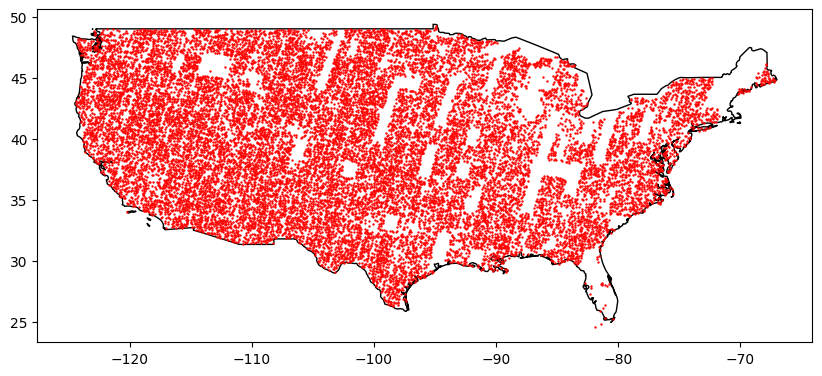

In [18]:
# plot the points
fig, ax = plt.subplots(figsize=(10, 10))
split_gdf.plot(ax=ax, color='white', edgecolor='black')
gdf_coords_nlcd.plot(ax=ax, color='red', markersize=.5)

In [19]:
gdf_coords_nlcd

,id,longitude,latitude,coords,org_shapes,n_nodata_lc,n_nodata_lu,geometry
0,19846,-118.259964,48.700012,"[[-118.29545356991427, 48.735372306771644], [-...","(263, 264)",0,64270,POINT (-118.25996 48.70001)
1,11863,-94.967291,38.652950,"[[-95.00269748896685, 38.68831095810865], [-94...","(263, 264)",0,65976,POINT (-94.96729 38.65295)
2,10276,-100.746637,42.218376,"[[-100.78208545195496, 42.253737191717825], [-...","(263, 265)",0,69315,POINT (-100.74664 42.21838)
3,23874,-105.597526,45.094092,"[[-105.63301926445924, 45.12958660708532], [-1...","(265, 265)",0,69003,POINT (-105.59753 45.09409)
4,3541,-93.731713,46.644204,"[[-93.76725684526953, 46.67969858767494], [-93...","(265, 265)",0,68961,POINT (-93.73171 46.64420)
...,...,...,...,...,...,...,...,...
18730,16154,-118.803062,36.114855,"[[-118.83855016468996, 36.15021545262209], [-1...","(263, 265)",0,65372,POINT (-118.80306 36.11485)
18731,18848,-123.005593,45.758731,"[[-123.04112519568632, 45.79409171863969], [-1...","(263, 265)",0,66420,POINT (-123.00559 45.75873)
18732,29033,-90.857823,34.419210,"[[-90.8933389322475, 34.454570359211516], [-90...","(263, 265)",0,67925,POINT (-90.85782 34.41921)
18733,3472,-87.960956,38.103425,"[[-87.99640996623799, 38.13878618724297], [-87...","(263, 264)",0,64380,POINT (-87.96096 38.10343)


## shuffle the indexes and create lmdb

In [20]:
fp_new_csv_nlcd = os.path.join(fd_used_csv, 'center_coords_nlcd.csv')
shuffled_indexes = np.random.permutation(len(gdf_coords_nlcd))
new_gdf_coords_nlcd = gdf_coords_nlcd.iloc[shuffled_indexes]
new_gdf_coords_nlcd.reset_index(drop=True, inplace=True)
new_points_nlcd = new_gdf_coords_nlcd.loc[:, ['id', 'longitude', 'latitude', 'coords', 'n_nodata_lu']]
new_points_nlcd.to_csv(fp_new_csv_nlcd, index=False)
new_gdf_coords_nlcd

,id,longitude,latitude,coords,org_shapes,n_nodata_lc,n_nodata_lu,geometry
0,17889,-101.616551,43.388984,"[[-101.65207756157494, 43.42434525164439], [-1...","(263, 265)",0,68228,POINT (-101.61655 43.38898)
1,10535,-124.110412,43.186875,"[[-124.14591866912501, 43.222369604741175], [-...","(265, 265)",0,66933,POINT (-124.11041 43.18688)
2,15368,-122.878975,47.524986,"[[-122.9144629622374, 47.56047998627311], [-12...","(265, 264)",0,65970,POINT (-122.87898 47.52499)
3,23526,-115.139693,43.478000,"[[-115.17517400196411, 43.51349391808516], [-1...","(265, 264)",0,69018,POINT (-115.13969 43.47800)
4,3013,-107.837876,32.691998,"[[-107.8733557363904, 32.72735845006561], [-10...","(263, 265)",0,68634,POINT (-107.83788 32.69200)
...,...,...,...,...,...,...,...,...
18730,22341,-88.715604,46.547040,"[[-88.75108452704518, 46.5825337218625], [-88....","(264, 265)",0,67397,POINT (-88.71560 46.54704)
18731,16798,-101.142874,34.830907,"[[-101.17834350800979, 34.86626764458504], [-1...","(263, 264)",0,68866,POINT (-101.14287 34.83091)
18732,10271,-109.711401,42.856530,"[[-109.74681495347403, 42.892024364317095], [-...","(265, 263)",0,68077,POINT (-109.71140 42.85653)
18733,25024,-121.609842,47.232831,"[[-121.64531541686497, 47.26819133651682], [-1...","(263, 265)",0,68274,POINT (-121.60984 47.23283)


In [21]:
fp_lmdb = os.path.join(fd_lmdb, 'nlcd.lmdb')
gsize = 75
img_names = ['toa', 'sr', 'nlcd_landcover_2019', 'nlcd_impervious_2019']
keys = ['toa', 'sr', 'lc', 'imp']

create_lmdb(fdir_nlcd_data, fp_lmdb, gsize, new_gdf_coords_nlcd.id, img_names, keys)

100%|██████████| 18735/18735 [51:23<00:00,  6.08it/s] 


Read data into /p/scratch/hai_dm4eo/liu_ch/data/WeakFT/weak_lmdbs/nlcd.lmdb|Elapsed time: 0:51:56


6380 6380 (11, 264, 264) (264, 264) 74941 37470 ['toa', 'sr', 'lc', 'imp']


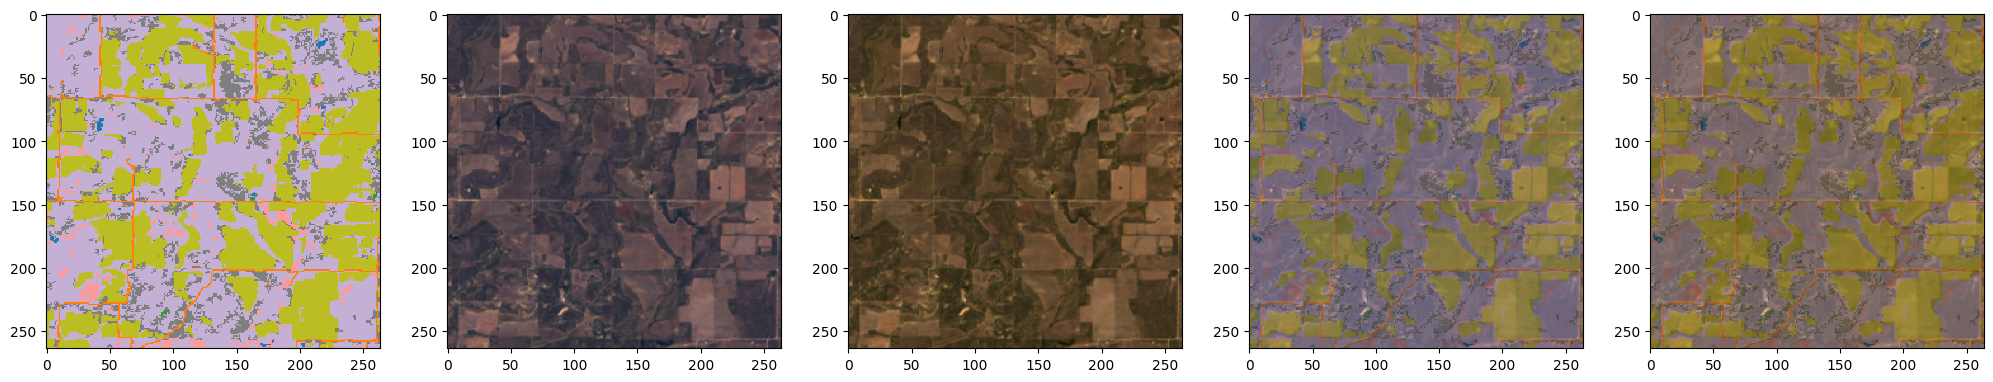

In [39]:
# check saved lmdb file
i = 500
lbl_k = 'lc'
fp_lmdb = os.path.join(fd_lmdb, 'nlcd.lmdb')
env = lmdb.open(fp_lmdb, max_readers=1, readonly=True, lock=False, readahead=False, meminit=False)
with env.begin(write=False) as txn:
    n_items = txn.stat()['entries']
    keys = pickle.loads(txn.get('keys'.encode()))
    img_obj = pickle.loads(txn.get((f'{i}_toa').encode()))
    imgs_obj = pickle.loads(txn.get((f'{i}_sr').encode()))
    lbl_obj = pickle.loads(txn.get((f'{i}_{lbl_k}').encode()))
    img = np.frombuffer(img_obj[0], dtype=np.float32).reshape(img_obj[1])
    imgs = np.frombuffer(imgs_obj[0], dtype=np.uint16).reshape(imgs_obj[1])
    lbl = np.frombuffer(lbl_obj[0], dtype=np.uint8).reshape(lbl_obj[1]).squeeze()
    print(img_obj[-1], lbl_obj[-1], img.shape, lbl.shape, n_items, int((n_items-1)//2), keys)
    plt.figure(figsize=(25, 5))
    plt.subplot(151)
    plt.imshow(lbl, cmap='tab20', interpolation='none')
    plt.subplot(152)
    im = img[[3,2,1]].transpose(1,2,0)
    im = (im - np.min(im)) / (np.max(im) - np.min(im))
    plt.imshow(im)
    plt.subplot(153)
    ims = imgs[[3,2,1]].transpose(1,2,0)
    ims = (ims - np.min(ims)) / (np.max(ims) - np.min(ims))
    plt.imshow(ims)
    plt.subplot(154)
    plt.imshow(im)
    plt.imshow(lbl, cmap='tab20', alpha=0.4, interpolation='none')
    plt.subplot(155)
    plt.imshow(ims)
    plt.imshow(lbl, cmap='tab20', alpha=0.4, interpolation='none')

## calculate mean and std

In [20]:
# mean and std
n_img = 4
fp_lmdb = os.path.join(fd_lmdb, 'nlcd.lmdb')
env = lmdb.open(fp_lmdb, max_readers=1, readonly=True, lock=False, readahead=False, meminit=False)
meant, stdt = [], []
means, stds = [], []
with env.begin(write=False) as txn:
    n_items = int(txn.stat()['entries']//n_img)
    for i in range(n_items):
        img_obj = pickle.loads(txn.get((f'{i}_toa').encode()))
        imgs_obj = pickle.loads(txn.get((f'{i}_sr').encode()))
        img = np.frombuffer(img_obj[0], dtype=np.float32).reshape(img_obj[1])
        imgs = np.frombuffer(imgs_obj[0], dtype=np.uint16).reshape(imgs_obj[1]).astype(np.float32)
        meant.append(img.mean(axis=(1,2)))
        stdt.append(img.std(axis=(1,2)))
        means.append(imgs.mean(axis=(1,2)))
        stds.append(imgs.std(axis=(1,2)))
meant, stdt = np.stack(meant, axis=0), np.stack(stdt, axis=0)
means, stds = np.stack(means, axis=0), np.stack(stds, axis=0)
# overall means and stds
meant_overall_nlcd = meant.mean(axis=0)
stdt_overall_nlcd = np.sqrt(np.mean(stdt**2 + meant**2, axis=0) - meant_overall_nlcd**2)
means_overall_nlcd = means.mean(axis=0)
stds_overall_nlcd = np.sqrt(np.mean(stds**2 + means**2, axis=0) - means_overall_nlcd**2)
print(f'TOA: mean={meant_overall_nlcd}, std={stdt_overall_nlcd}')
print(f'SR: mean={means_overall_nlcd}, std={stds_overall_nlcd}')

TOA: mean=[1.27162933e-01 1.11561865e-01 1.05153576e-01 1.05786517e-01
 2.62852758e-01 2.25046128e-01 1.48086548e-01 1.03540123e-01
 2.22910964e-03 3.00991119e+02 2.99805695e+02], std=[2.6661083e-02 3.2774147e-02 4.2541582e-02 6.3744433e-02 8.2557537e-02
 9.5190331e-02 8.9534022e-02 4.9409326e-02 3.4905171e-03 1.0144272e+01
 9.5647469e+00]
SR: mean=[ 8845.307  9203.866 10285.372 10701.469 16744.148 15734.601 13015.599], std=[1259.7809 1473.293  1843.4121 2584.7322 3067.3977 3586.7556 3458.8877]


## class proportions

In [10]:
fp_lmdb = os.path.join(fd_lmdb, 'nlcd.lmdb')
key_list = ['lc', 'imp']
lbls = {k:[] for k in key_list}
env = lmdb.open(fp_lmdb, max_readers=1, readonly=True, lock=False, readahead=False, meminit=False)
with env.begin(write=False) as txn:
    n_items = txn.stat()['entries']
    keys = pickle.loads(txn.get('keys'.encode()))
    print(keys, n_items)
    for i in range(int((n_items-1)//4)):
        for k in key_list:
            lbl_obj = pickle.loads(txn.get((f'{i}_{k}').encode()))
            lbl = np.frombuffer(lbl_obj[0], dtype=np.uint8).reshape(lbl_obj[1]).squeeze()
            lbls[k].append(lbl)

for k in key_list:
    lbls_ = np.dstack(lbls[k])
    uni_vs = np.unique(lbls_)
    print(f'key={k}', lbls_.shape, uni_vs)
    for uni_v in uni_vs:
        na = np.sum(lbls_==uni_v)
        print(f'{uni_v}: {na}, {na/lbls_.size*100:.2f}%')

['toa', 'sr', 'lc', 'imp'] 74941
key=lc (264, 264, 18735) [11 12 21 22 23 24 31 41 42 43 52 71 81 82 90 95]
11: 26369842, 2.02%
12: 49566, 0.00%
21: 28108682, 2.15%
22: 14300243, 1.10%
23: 7008673, 0.54%
24: 2067420, 0.16%
31: 14586764, 1.12%
41: 109319944, 8.37%
42: 163535920, 12.52%
43: 38452673, 2.94%
52: 347268034, 26.60%
71: 208253621, 15.95%
81: 66976788, 5.13%
82: 210195813, 16.10%
90: 51556236, 3.95%
95: 17704341, 1.36%
key=imp (264, 264, 18735) [ 0 20 21 22 23 24 25 26 27 28 29]
0: 1247780472, 95.56%
20: 1488335, 0.11%
21: 5384824, 0.41%
22: 27325112, 2.09%
23: 6489070, 0.50%
24: 16841852, 1.29%
25: 156, 0.00%
26: 11817, 0.00%
27: 8937, 0.00%
28: 88018, 0.01%
29: 335967, 0.03%


# USFS

In [26]:
# data points
fdir_usfs = os.path.join(fd_pdata, 'usfs')
fdir_usfs_data = os.path.join(fdir_usfs, 'data')
fdir_usfs_csv  = os.path.join(fdir_usfs, 'Mask_success_center_coords_usa_usfs.csv')
points_usfs = pd.read_csv(fdir_usfs_csv, header=0)
# Convert the DataFrame to a GeoDataFrame
gdf_coords_usfs = gpd.GeoDataFrame(points_usfs, geometry=gpd.points_from_xy(points_usfs.longitude, points_usfs.latitude))
len(gdf_coords_usfs)

18595

## plot spots - 18582

<Axes: >

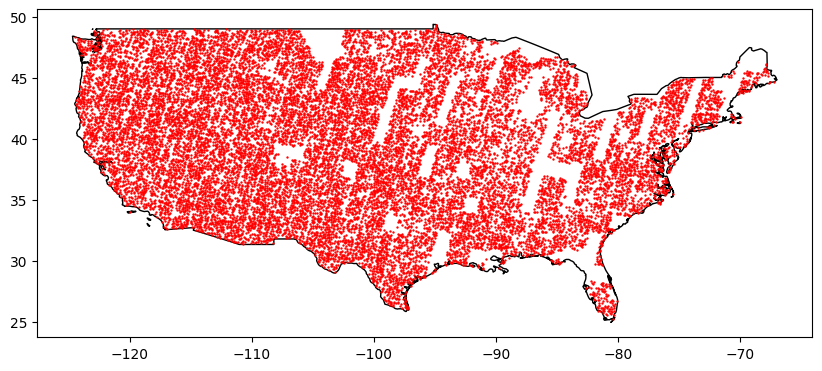

In [29]:
# plot the points
fig, ax = plt.subplots(figsize=(10, 10))
split_gdf.plot(ax=ax, color='white', edgecolor='black')
gdf_coords_usfs.plot(ax=ax, color='red', markersize=.5)

In [30]:
gdf_coords_usfs

,id,longitude,latitude,coords,org_shapes,n_nodata_lc,n_nodata_lu,geometry
0,0,-121.219561,43.073086,"[[-121.25500149511475, 43.108446869449494], [-...","(264, 264)",0,0,POINT (-121.21956 43.07309)
1,2,-84.246013,38.126740,"[[-84.28147780059004, 38.16223374680801], [-84...","(264, 265)",0,0,POINT (-84.24601 38.12674)
2,6,-91.776347,47.181517,"[[-91.81187794499152, 47.217010809488336], [-9...","(264, 264)",0,0,POINT (-91.77635 47.18152)
3,7,-110.296223,46.247474,"[[-110.33169390417441, 46.282968435625385], [-...","(264, 264)",0,0,POINT (-110.29622 46.24747)
4,8,-75.212009,44.136502,"[[-75.24749242932116, 44.17199626220317], [-75...","(264, 265)",0,0,POINT (-75.21201 44.13650)
...,...,...,...,...,...,...,...,...
18590,29437,-114.827280,33.682978,"[[-114.8627106649074, 33.71847227132786], [-11...","(264, 264)",0,0,POINT (-114.82728 33.68298)
18591,29438,-98.958734,38.635337,"[[-98.99423700235762, 38.67069742286734], [-98...","(264, 264)",0,0,POINT (-98.95873 38.63534)
18592,29439,-97.325266,40.625173,"[[-97.36065040919021, 40.66066742479717], [-97...","(264, 264)",0,0,POINT (-97.32527 40.62517)
18593,29440,-105.285865,31.893680,"[[-105.32137449834042, 31.92917420930223], [-1...","(264, 264)",0,0,POINT (-105.28587 31.89368)


In [31]:
(gdf_coords_usfs.n_nodata_lc!=0).sum(), (gdf_coords_usfs.n_nodata_lu!=0).sum()

(0, 0)

## shuffle the indexes and create lmdb

In [32]:
fp_new_csv_usfs = os.path.join(fd_used_csv, 'center_coords_usfs.csv')
shuffled_indexes = np.random.permutation(len(gdf_coords_usfs))
new_gdf_coords_usfs = gdf_coords_usfs.iloc[shuffled_indexes]
new_gdf_coords_usfs.reset_index(drop=True, inplace=True)
new_points_usfs = new_gdf_coords_usfs.loc[:, ['id', 'longitude', 'latitude', 'coords']]
new_points_usfs.to_csv(fp_new_csv_usfs, index=False)
new_gdf_coords_usfs

,id,longitude,latitude,coords,org_shapes,n_nodata_lc,n_nodata_lu,geometry
0,2104,-83.740568,39.294767,"[[-83.77608699507223, 39.33026164724155], [-83...","(264, 264)",0,0,POINT (-83.74057 39.29477)
1,13898,-93.057569,34.306346,"[[-93.09303642634103, 34.34170724149815], [-93...","(264, 264)",0,0,POINT (-93.05757 34.30635)
2,13496,-113.190700,39.508144,"[[-113.22622350432184, 39.54363796554584], [-1...","(264, 264)",0,0,POINT (-113.19070 39.50814)
3,12225,-71.849468,41.622967,"[[-71.88498648305186, 41.65846132683193], [-71...","(264, 265)",0,0,POINT (-71.84947 41.62297)
4,8118,-79.987055,34.499347,"[[-80.02249389040601, 34.53470764117084], [-79...","(264, 264)",0,0,POINT (-79.98706 34.49935)
...,...,...,...,...,...,...,...,...
18590,10565,-113.732156,36.355377,"[[-113.7676442220151, 36.39073735082948], [-11...","(264, 264)",0,0,POINT (-113.73216 36.35538)
18591,971,-95.362831,34.162438,"[[-95.39834970841542, 34.197798929857186], [-9...","(264, 264)",0,0,POINT (-95.36283 34.16244)
18592,17322,-114.351159,34.790149,"[[-114.38661102755479, 34.82550961863503], [-1...","(264, 264)",0,0,POINT (-114.35116 34.79015)
18593,13493,-72.536305,44.803196,"[[-72.57180874691498, 44.83868997430345], [-72...","(264, 264)",0,0,POINT (-72.53630 44.80320)


In [33]:
fp_lmdb = os.path.join(fd_lmdb, 'usfs.lmdb')
gsize = 75
img_names = ['toa', 'sr', 'usfs_landcover_2023', 'usfs_landuse_2023']
keys = ['toa', 'sr', 'lc', 'lu']

create_lmdb(fdir_usfs_data, fp_lmdb, gsize, new_gdf_coords_usfs.id, img_names, keys)

100%|██████████| 18595/18595 [42:57<00:00,  7.21it/s]  


Read data into /p/scratch/hai_dm4eo/liu_ch/data/WeakFT/weak_lmdbs/usfs.lmdb|Elapsed time: 0:43:36


540 540 (11, 264, 264) (264, 264) 74381 18595 ['toa', 'sr', 'lc', 'lu']


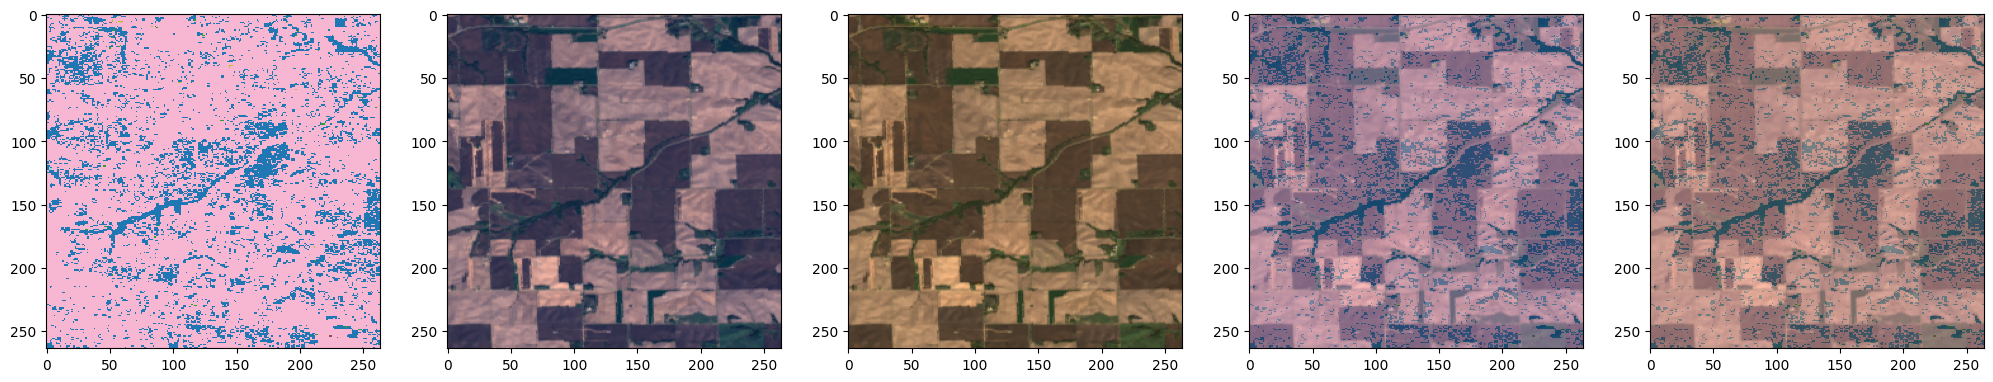

In [34]:
# check saved lmdb file
i = 200
lbl_k = 'lc'
fp_lmdb = os.path.join(fd_lmdb, 'usfs.lmdb')
env = lmdb.open(fp_lmdb, max_readers=1, readonly=True, lock=False, readahead=False, meminit=False)
with env.begin(write=False) as txn:
    n_items = txn.stat()['entries']
    keys = pickle.loads(txn.get('keys'.encode()))
    img_obj = pickle.loads(txn.get((f'{i}_toa').encode()))
    imgs_obj = pickle.loads(txn.get((f'{i}_sr').encode()))
    lbl_obj = pickle.loads(txn.get((f'{i}_{lbl_k}').encode()))
    img = np.frombuffer(img_obj[0], dtype=np.float32).reshape(img_obj[1])
    imgs = np.frombuffer(imgs_obj[0], dtype=np.uint16).reshape(imgs_obj[1])
    lbl = np.frombuffer(lbl_obj[0], dtype=np.uint8).reshape(lbl_obj[1]).squeeze()
    print(img_obj[-1], lbl_obj[-1], img.shape, lbl.shape, n_items, int((n_items-1)//4), keys)
    plt.figure(figsize=(25, 5))
    plt.subplot(151)
    plt.imshow(lbl, cmap='tab20', interpolation='none')
    plt.subplot(152)
    im = img[[3,2,1]].transpose(1,2,0)
    im = (im - np.min(im)) / (np.max(im) - np.min(im))
    plt.imshow(im)
    plt.subplot(153)
    ims = imgs[[3,2,1]].transpose(1,2,0)
    ims = (ims - np.min(ims)) / (np.max(ims) - np.min(ims))
    plt.imshow(ims)
    plt.subplot(154)
    plt.imshow(im)
    plt.imshow(lbl, cmap='tab20', alpha=0.4, interpolation='none')
    plt.subplot(155)
    plt.imshow(ims)
    plt.imshow(lbl, cmap='tab20', alpha=0.4, interpolation='none')

sr: uint16, (7, 264, 264)


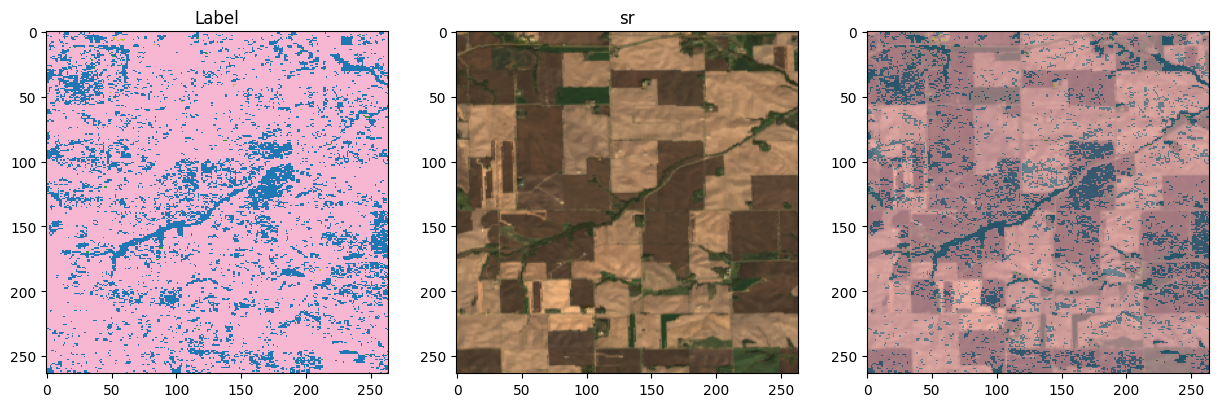

In [36]:
# lbl_k = 'lu'
lbl_name = 'usfs_landcover_2023' if lbl_k == 'lc' else 'usfs_landuse_2023'
show_image_example(fdir_usfs_data, img_obj[-1], img_names=['sr'], img_bands=[3,2,1], lbl_name=lbl_name, alpha=0.5, print_dtypes=True)  # img_obj[-1]

## calculate mean and std

In [26]:
# mean and std
n_img = 4
fp_lmdb = os.path.join(fd_lmdb, 'usfs.lmdb')
env = lmdb.open(fp_lmdb, max_readers=1, readonly=True, lock=False, readahead=False, meminit=False)
meant, stdt = [], []
means, stds = [], []
with env.begin(write=False) as txn:
    n_items = int(txn.stat()['entries']//n_img)
    for i in range(n_items):
        img_obj = pickle.loads(txn.get((f'{i}_toa').encode()))
        imgs_obj = pickle.loads(txn.get((f'{i}_sr').encode()))
        img = np.frombuffer(img_obj[0], dtype=np.float32).reshape(img_obj[1])
        imgs = np.frombuffer(imgs_obj[0], dtype=np.uint16).reshape(imgs_obj[1]).astype(np.float32)
        meant.append(img.mean(axis=(1,2)))
        stdt.append(img.std(axis=(1,2)))
        means.append(imgs.mean(axis=(1,2)))
        stds.append(imgs.std(axis=(1,2)))
meant, stdt = np.stack(meant, axis=0), np.stack(stdt, axis=0)
means, stds = np.stack(means, axis=0), np.stack(stds, axis=0)
# overall means and stds
meant_overall_usfs = meant.mean(axis=0)
stdt_overall_usfs = np.sqrt(np.mean(stdt**2 + meant**2, axis=0) - meant_overall_usfs**2)
means_overall_usfs = means.mean(axis=0)
stds_overall_usfs = np.sqrt(np.mean(stds**2 + means**2, axis=0) - means_overall_usfs**2)
print(n_items, meant.shape, stdt.shape, means.shape, stds.shape)
print(f'TOA: mean={meant_overall_usfs}, std={stdt_overall_usfs}')
print(f'SR: mean={means_overall_usfs}, std={stds_overall_usfs}')

18582 (18582, 11) (18582, 11) (18582, 7) (18582, 7)
TOA: mean=[1.3031135e-01 1.1548932e-01 1.0973417e-01 1.1077589e-01 2.6778254e-01
 2.3235151e-01 1.5616804e-01 1.0803408e-01 2.0008080e-03 3.0310034e+02
 3.0169684e+02], std=[3.30185518e-02 3.84677909e-02 4.67350185e-02 6.74401373e-02
 8.56838375e-02 1.00014724e-01 9.49275419e-02 5.27144931e-02
 2.50696135e-03 9.69253922e+00 9.27867222e+00]
SR: mean=[ 8931.157  9326.412 10448.886 10865.018 16921.568 16003.465 13326.068], std=[1630.9384 1805.5847 2083.4126 2789.4658 3211.4546 3770.6658 3670.7993]


In [14]:
img.min(axis=(1,2)), img.max(axis=(1,2))

(array([1.12019025e-01, 8.61261487e-02, 5.76742515e-02, 3.54960822e-02,
        7.47068673e-02, 2.70210467e-02, 1.54641839e-02, 5.02689146e-02,
        1.10065368e-04, 2.96963623e+02, 2.95609955e+02], dtype=float32),
 array([2.3270570e-01, 2.3969485e-01, 2.2519374e-01, 2.5353557e-01,
        5.3461498e-01, 3.8916361e-01, 2.7290708e-01, 2.1108989e-01,
        2.2838563e-03, 3.0302194e+02, 3.0029135e+02], dtype=float32))

## class proportions

In [4]:
fp_lmdb = os.path.join(fd_lmdb, 'usfs.lmdb')
key_list = ['lc', 'lu']
lbls = {k:[] for k in key_list}
env = lmdb.open(fp_lmdb, max_readers=1, readonly=True, lock=False, readahead=False, meminit=False)
with env.begin(write=False) as txn:
    n_items = txn.stat()['entries']
    keys = pickle.loads(txn.get('keys'.encode()))
    print(keys, n_items)
    for i in range(int((n_items-1)//4)):
        for k in key_list:
            lbl_obj = pickle.loads(txn.get((f'{i}_{k}').encode()))
            lbl = np.frombuffer(lbl_obj[0], dtype=np.uint8).reshape(lbl_obj[1]).squeeze()
            lbls[k].append(lbl)

for k in key_list:
    lbls_ = np.dstack(lbls[k])
    uni_vs = np.unique(lbls_)
    print(f'key={k}', lbls_.shape, uni_vs)
    for uni_v in uni_vs:
        na = np.sum(lbls_==uni_v)
        print(f'{uni_v}: {na}, {na/lbls_.size*100:.2f}%')

['toa', 'sr', 'lc', 'lu'] 74381
key=lc (264, 264, 18595) [ 1  3  4  5  7  8  9 10 11 12 13 14 15]
1: 440816096, 34.01%
3: 3436010, 0.27%
4: 48522441, 3.74%
5: 627903, 0.05%
7: 55447443, 4.28%
8: 168269984, 12.98%
9: 33366894, 2.57%
10: 465096256, 35.89%
11: 222489, 0.02%
12: 54854071, 4.23%
13: 23205, 0.00%
14: 25217568, 1.95%
15: 96760, 0.01%
key=lu (264, 264, 18595) [1 2 3 4 5 6 7]
1: 220188633, 16.99%
2: 37424802, 2.89%
3: 479434840, 36.99%
4: 9633746, 0.74%
5: 36436709, 2.81%
6: 512781594, 39.57%
7: 96796, 0.01%


In [6]:
lbls_array = {}
for k in lbls:
    lbls_array[k] = np.dstack(lbls[k])
    print(k, lbls_array[k].shape)
tmp = lbls_array['lc'][lbls_array['lu']==1]
uni_tmp = np.unique(tmp)
print(tmp.shape, uni_tmp)
for uni_t in uni_tmp:
    na = np.sum(tmp==uni_t)
    print(f'{uni_t}: {na}, {na/tmp.size*100:.2f}%')

lc (264, 264, 18595)
lu (264, 264, 18595)
(220188633,) [ 1  3  4  5  7  8  9 10 11 12 14]
1: 6367805, 2.89%
3: 1386, 0.00%
4: 717071, 0.33%
5: 110, 0.00%
7: 225150, 0.10%
8: 1892028, 0.86%
9: 239570, 0.11%
10: 209671940, 95.22%
11: 354, 0.00%
12: 1025617, 0.47%
14: 47602, 0.02%


# sbtn

In [21]:
# data points
fdir_sbtn = os.path.join(fd_pdata, 'sbtn')
fdir_sbtn_data = os.path.join(fdir_sbtn, 'data')
fdir_sbtn_csv  = os.path.join(fdir_sbtn, 'Mask_success_center_coords_usa_sbtn.csv')
points_sbtn = pd.read_csv(fdir_sbtn_csv, header=0)
# Convert the DataFrame to a GeoDataFrame
gdf_coords_sbtn = gpd.GeoDataFrame(points_sbtn, geometry=gpd.points_from_xy(points_sbtn.longitude, points_sbtn.latitude))
len(gdf_coords_sbtn)

22697

In [23]:
gdf_coords_sbtn

,id,longitude,latitude,coords,org_shapes,n_nodata_lc,geometry
0,494577,86.570645,51.290176,"[[86.53514728365485, 51.32553678534508], [86.6...","(264, 265)",0,POINT (86.57064 51.29018)
1,718312,60.526947,27.691922,"[[60.49152822075302, 27.727415911307496], [60....","(264, 264)",0,POINT (60.52695 27.69192)
2,96672,26.224776,43.524205,"[[26.189365522521992, 43.55956567548765], [26....","(264, 264)",0,POINT (26.22478 43.52420)
3,911808,23.131794,14.568547,"[[23.09642258132369, 14.604041365757675], [23....","(264, 264)",0,POINT (23.13179 14.56855)
4,876559,70.576958,43.316092,"[[70.54147418249431, 43.351586278392084], [70....","(264, 265)",0,POINT (70.57696 43.31609)
...,...,...,...,...,...,...,...
22692,473204,32.971046,17.810335,"[[32.935607320152464, 17.84582960381328], [33....","(264, 264)",0,POINT (32.97105 17.81034)
22693,599611,38.450031,39.201733,"[[38.41455869439608, 39.237226973409015], [38....","(264, 265)",0,POINT (38.45003 39.20173)
22694,107535,81.663306,22.451041,"[[81.62794744316493, 22.486401727625278], [81....","(264, 264)",0,POINT (81.66331 22.45104)
22695,949823,80.106305,48.958580,"[[80.07080927826229, 48.993940283274576], [80....","(264, 265)",0,POINT (80.10630 48.95858)


## plot spots - 22687

<Axes: >

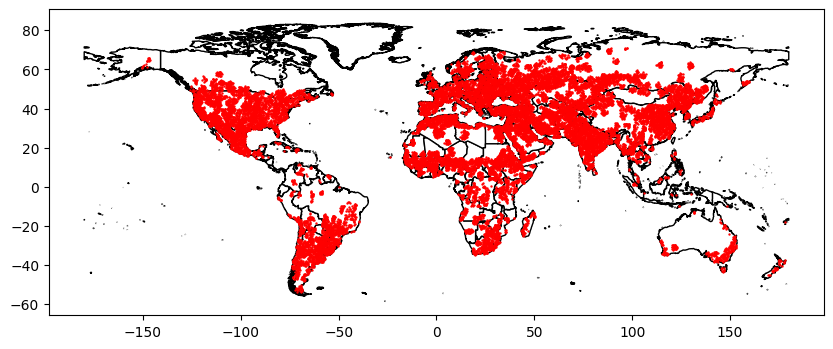

In [22]:
# plot the points
fig, ax = plt.subplots(figsize=(10, 10))
world_shapefile.plot(ax=ax, color='white', edgecolor='black')
gdf_coords_sbtn.plot(ax=ax, color='red', markersize=.5)

## shuffle the indexes and create lmdb

In [24]:
fp_new_csv_sbtn = os.path.join(fd_used_csv, 'center_coords_sbtn.csv')
shuffled_indexes = np.random.permutation(len(gdf_coords_sbtn))
new_gdf_coords_sbtn = gdf_coords_sbtn.iloc[shuffled_indexes]
new_gdf_coords_sbtn.reset_index(drop=True, inplace=True)
new_points_sbtn = new_gdf_coords_sbtn.loc[:, ['id', 'longitude', 'latitude', 'coords']]
new_points_sbtn.to_csv(fp_new_csv_sbtn, index=False)
new_gdf_coords_sbtn

,id,longitude,latitude,coords,org_shapes,n_nodata_lc,geometry
0,569217,13.745183,58.933318,"[[13.709671149893802, 58.96867864377922], [13....","(264, 265)",0,POINT (13.74518 58.93332)
1,147654,10.660140,52.454124,"[[10.624639707532639, 52.48961824469669], [10....","(264, 264)",0,POINT (10.66014 52.45412)
2,870765,-4.128879,17.402402,"[[-4.164365356710699, 17.437896268940605], [-4...","(264, 264)",0,POINT (-4.12888 17.40240)
3,584951,89.460027,28.632467,"[[89.42453376132485, 28.667827772817038], [89....","(264, 264)",0,POINT (89.46003 28.63247)
4,532597,-9.394866,13.437586,"[[-9.430193500034543, 13.473079751260032], [-9...","(264, 264)",0,POINT (-9.39487 13.43759)
...,...,...,...,...,...,...,...
22692,192870,94.579377,20.850491,"[[94.54391321254498, 20.88598513039014], [94.6...","(264, 264)",0,POINT (94.57938 20.85049)
22693,219461,105.147662,35.939518,"[[105.11214379720934, 35.975011954290046], [10...","(264, 264)",0,POINT (105.14766 35.93952)
22694,325736,-71.819980,18.908565,"[[-71.8553884543828, 18.94405944745138], [-71....","(264, 264)",0,POINT (-71.81998 18.90857)
22695,227137,-112.352188,49.694041,"[[-112.38768691432087, 49.729401399399684], [-...","(264, 265)",0,POINT (-112.35219 49.69404)


In [25]:
fp_lmdb = os.path.join(fd_lmdb, 'sbtn.lmdb')
gsize = 90
img_names = ['toa', 'sr', 'sbtn_landcover_2020']
keys = ['toa', 'sr', 'lc']

create_lmdb(fdir_sbtn_data, fp_lmdb, gsize, new_gdf_coords_sbtn.id, img_names, keys)

100%|██████████| 22697/22697 [44:06<00:00,  8.58it/s]  


Read data into /p/scratch/hai_dm4eo/liu_ch/data/WeakFT/weak_lmdbs/sbtn.lmdb|Elapsed time: 0:44:54


888321 888321 (11, 264, 264) (264, 264) 68092 34045 ['toa', 'sr', 'lc']


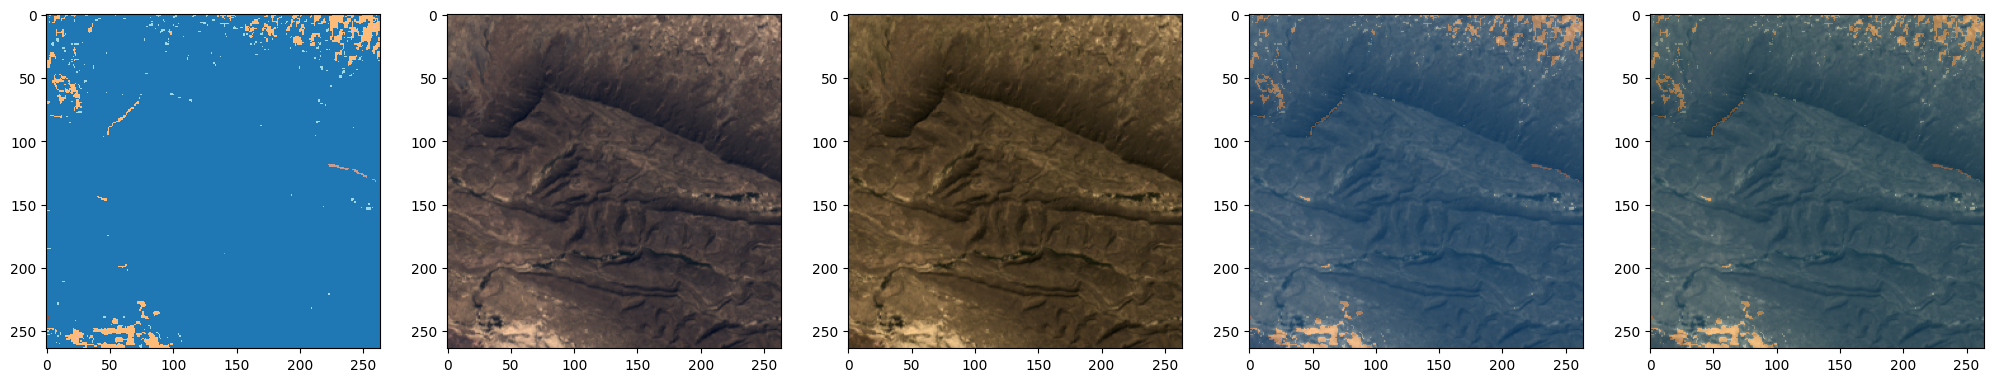

In [37]:
# check saved lmdb file
i = 200
lbl_k = 'lc'
fp_lmdb = os.path.join(fd_lmdb, 'sbtn.lmdb')
env = lmdb.open(fp_lmdb, max_readers=1, readonly=True, lock=False, readahead=False, meminit=False)
with env.begin(write=False) as txn:
    n_items = txn.stat()['entries']
    keys = pickle.loads(txn.get('keys'.encode()))
    img_obj = pickle.loads(txn.get((f'{i}_toa').encode()))
    imgs_obj = pickle.loads(txn.get((f'{i}_sr').encode()))
    lbl_obj = pickle.loads(txn.get((f'{i}_{lbl_k}').encode()))
    img = np.frombuffer(img_obj[0], dtype=np.float32).reshape(img_obj[1])
    imgs = np.frombuffer(imgs_obj[0], dtype=np.uint16).reshape(imgs_obj[1])
    lbl = np.frombuffer(lbl_obj[0], dtype=np.uint8).reshape(lbl_obj[1]).squeeze()
    print(img_obj[-1], lbl_obj[-1], img.shape, lbl.shape, n_items, int((n_items-1)//2), keys)
    plt.figure(figsize=(25, 5))
    plt.subplot(151)
    plt.imshow(lbl, cmap='tab20', interpolation='none')
    plt.subplot(152)
    im = img[[3,2,1]].transpose(1,2,0)
    im = (im - np.min(im)) / (np.max(im) - np.min(im))
    plt.imshow(im)
    plt.subplot(153)
    ims = imgs[[3,2,1]].transpose(1,2,0)
    ims = (ims - np.min(ims)) / (np.max(ims) - np.min(ims))
    plt.imshow(ims)
    plt.subplot(154)
    plt.imshow(im)
    plt.imshow(lbl, cmap='tab20', alpha=0.4, interpolation='none')
    plt.subplot(155)
    plt.imshow(ims)
    plt.imshow(lbl, cmap='tab20', alpha=0.4, interpolation='none')

sr: uint16, (7, 264, 264)


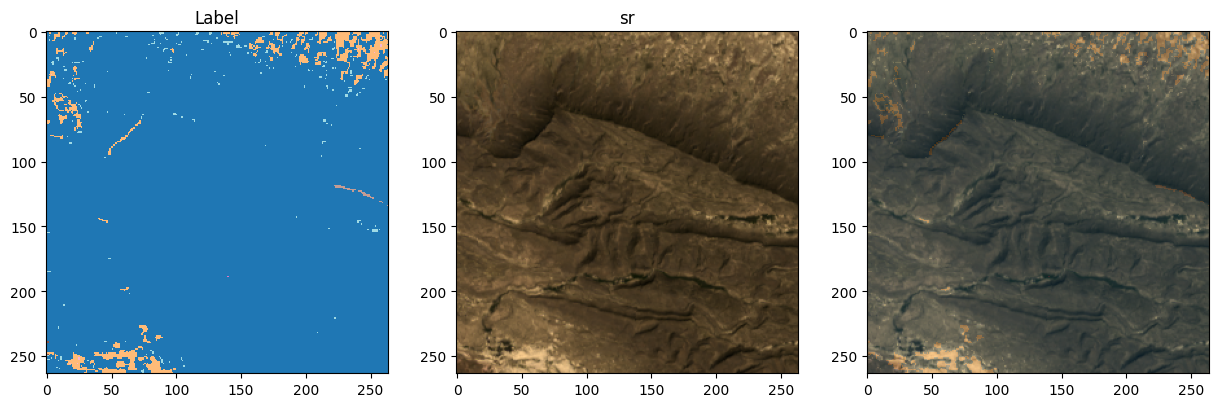

In [38]:
show_image_example(fdir_sbtn_data, img_obj[-1], img_names=['sr'], img_bands=[3,2,1], lbl_name='sbtn_landcover_2020', alpha=0.2, print_dtypes=True)  # img_obj[-1]

## calculate mean and std

In [6]:
# check saved lmdb file
fp_lmdb = os.path.join(fd_lmdb, 'sbtn.lmdb')
env = lmdb.open(fp_lmdb, max_readers=1, readonly=True, lock=False, readahead=False, meminit=False)
meant, stdt = [], []
means, stds = [], []
with env.begin(write=False) as txn:
    n_items = int(txn.stat()['entries']//3)
    for i in range(n_items):
        img_obj = pickle.loads(txn.get((f'{i}_toa').encode()))
        imgs_obj = pickle.loads(txn.get((f'{i}_sr').encode()))
        img = np.frombuffer(img_obj[0], dtype=np.float32).reshape(img_obj[1])
        imgs = np.frombuffer(imgs_obj[0], dtype=np.uint16).reshape(imgs_obj[1]).astype(np.float32)
        meant.append(img.mean(axis=(1,2)))
        stdt.append(img.std(axis=(1,2)))
        means.append(imgs.mean(axis=(1,2)))
        stds.append(imgs.std(axis=(1,2)))
meant, stdt = np.stack(meant, axis=0), np.stack(stdt, axis=0)
means, stds = np.stack(means, axis=0), np.stack(stds, axis=0)
# overall means and stds
meant_overall_sbtn = meant.mean(axis=0)
stdt_overall_sbtn = np.sqrt(np.mean(stdt**2 + meant**2, axis=0) - meant_overall_sbtn**2)
means_overall_sbtn = means.mean(axis=0)
stds_overall_sbtn = np.sqrt(np.mean(stds**2 + means**2, axis=0) - means_overall_sbtn**2)
print(f'TOA: mean={meant_overall_sbtn}, std={stdt_overall_sbtn}')
print(f'SR: mean={means_overall_sbtn}, std={stds_overall_sbtn}')
print(f"TOA: mean={[f'{i:.04f}' for i in meant_overall_sbtn]}, std={[f'{i:.04f}' for i in stdt_overall_sbtn]}")
print(f"SR: mean={[f'{i:.04f}' for i in means_overall_sbtn]}, std={[f'{i:.04f}' for i in stds_overall_sbtn]}")

TOA: mean=[1.39721155e-01 1.25081092e-01 1.23868674e-01 1.31810322e-01
 2.83200920e-01 2.46309161e-01 1.71668261e-01 1.24766774e-01
 2.41818046e-03 3.02881165e+02 3.01475922e+02], std=[4.8360974e-02 5.4451246e-02 6.7494757e-02 9.9091828e-02 9.8961689e-02
 1.3054624e-01 1.2400048e-01 7.7818833e-02 4.7299736e-03 1.0850907e+01
 1.0487716e+01]
SR: mean=[ 9129.262  9584.849 10972.924 11666.224 17488.928 16536.77  13952.874], std=[2375.5134 2545.028  2975.2673 4044.3245 3713.504  4925.688  4821.258 ]
TOA: mean=['0.1397', '0.1251', '0.1239', '0.1318', '0.2832', '0.2463', '0.1717', '0.1248', '0.0024', '302.8812', '301.4759'], std=['0.0484', '0.0545', '0.0675', '0.0991', '0.0990', '0.1305', '0.1240', '0.0778', '0.0047', '10.8509', '10.4877']
SR: mean=['9129.2617', '9584.8486', '10972.9238', '11666.2236', '17488.9277', '16536.7695', '13952.8740'], std=['2375.5134', '2545.0281', '2975.2673', '4044.3245', '3713.5039', '4925.6880', '4821.2578']


## class proportions

In [12]:
fp_lmdb = os.path.join(fd_lmdb, 'sbtn.lmdb')
labels = []
env = lmdb.open(fp_lmdb, max_readers=1, readonly=True, lock=False, readahead=False, meminit=False)
with env.begin(write=False) as txn:
    n_items = txn.stat()['entries']
    keys = pickle.loads(txn.get('keys'.encode()))
    for i in range(int((n_items-1)//3)):
        lbl_obj = pickle.loads(txn.get((f'{i}_lc').encode()))
        lbl = np.frombuffer(lbl_obj[0], dtype=np.uint8).reshape(lbl_obj[1]).squeeze()
        labels.append(lbl)
labels = np.dstack(labels)
uni_vs = np.unique(labels)
print(n_items, keys, labels.shape, uni_vs)
for uni_v in uni_vs:
    na = np.sum(labels==uni_v)
    print(f'{uni_v}: {na}, {na/labels.size*100:.2f}%')

68092 ['toa', 'sr', 'lc'] (264, 264, 22697) [ 2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24 25
 26]
2: 293169345, 18.53%
3: 350174700, 22.14%
4: 32322713, 2.04%
5: 137534, 0.01%
6: 212819096, 13.45%
7: 373903, 0.02%
8: 15409952, 0.97%
9: 19569085, 1.24%
10: 22357232, 1.41%
11: 15499195, 0.98%
12: 418104878, 26.43%
13: 75901772, 4.80%
14: 48749412, 3.08%
15: 62636026, 3.96%
16: 72473, 0.00%
17: 2133829, 0.13%
18: 2073034, 0.13%
19: 1538184, 0.10%
20: 799924, 0.05%
21: 8047807, 0.51%
22: 4, 0.00%
23: 1, 0.00%
24: 3, 0.00%
25: 3, 0.00%
26: 7, 0.00%


original sbtn:
TOA: mean=[1.3973607e-01 1.2510014e-01 1.2389462e-01 1.3185014e-01 2.8322396e-01
 2.4637008e-01 1.7172308e-01 1.2479819e-01 2.4182030e-03 3.0288559e+02
 3.0148013e+02], std=[4.83666174e-02 5.44560663e-02 6.74990192e-02 9.90959033e-02
 9.89683494e-02 1.30543843e-01 1.24001555e-01 7.78222680e-02
 4.73055523e-03 1.08487473e+01 1.04910679e+01]
SR: mean=[ 9129.848  9585.586 10973.983 11667.794 17489.87  16538.992 13954.958], std=[2375.867  2545.3613 2975.5752 4044.4946 3713.2583 4925.824  4821.4604]

TOA: mean=[1.3031135e-01 1.1548932e-01 1.0973417e-01 1.1077589e-01 2.6778254e-01
 2.3235151e-01 1.5616804e-01 1.0803408e-01 2.0008080e-03 3.0310034e+02
 3.0169684e+02], std=[3.30185518e-02 3.84677909e-02 4.67350185e-02 6.74401373e-02
 8.56838375e-02 1.00014724e-01 9.49275419e-02 5.27144931e-02
 2.50696135e-03 9.69253922e+00 9.27867222e+00]
SR: mean=[ 8931.157  9326.412 10448.886 10865.018 16921.568 16003.465 13326.068], std=[1630.9384 1805.5847 2083.4126 2789.4658 3211.4546 3770.6658 3670.7993]

In [17]:
meant_overall_sbtn = meant.mean(axis=0)
stdt_overall_sbtn = np.sqrt(np.mean(stdt**2 + meant**2, axis=0) - meant_overall_sbtn**2)
means_overall_sbtn = means.mean(axis=0)
stds_overall_sbtn = np.sqrt(np.mean(stds**2 + means**2, axis=0) - means_overall_sbtn**2)

In [28]:
for i, (nlcd, usfs, sbtn) in enumerate(zip(meant_overall_nlcd, meant_overall_usfs, meant_overall_sbtn)):
    print(f'{i}:{nlcd:.4f}, {usfs:.4f}, {sbtn:.4f}')
print('------------------------------------')
for i, (nlcd, usfs, sbtn) in enumerate(zip(stdt_overall_nlcd, stdt_overall_usfs, stdt_overall_sbtn)):
    print(f'{i}:{nlcd:.4f}, {usfs:.4f}, {sbtn:.4f}')
print('------------------------------------')
for i, (nlcd, usfs, sbtn) in enumerate(zip(means_overall_nlcd, means_overall_usfs, means_overall_sbtn)):
    print(f'{i}:{nlcd:.4f}, {usfs:.4f}, {sbtn:.4f}')
print('------------------------------------')
for i, (nlcd, usfs, sbtn) in enumerate(zip(stds_overall_nlcd, stds_overall_usfs, stds_overall_sbtn)):
    print(f'{i}:{nlcd:.4f}, {usfs:.4f}, {sbtn:.4f}')

0:0.1272, 0.1303, 0.1397
1:0.1116, 0.1155, 0.1251
2:0.1052, 0.1097, 0.1239
3:0.1058, 0.1108, 0.1319
4:0.2629, 0.2678, 0.2832
5:0.2250, 0.2324, 0.2464
6:0.1481, 0.1562, 0.1717
7:0.1035, 0.1080, 0.1248
8:0.0022, 0.0020, 0.0024
9:300.9911, 303.1003, 302.8856
10:299.8057, 301.6968, 301.4801
------------------------------------
0:0.0267, 0.0330, 0.0484
1:0.0328, 0.0385, 0.0545
2:0.0425, 0.0467, 0.0675
3:0.0637, 0.0674, 0.0991
4:0.0826, 0.0857, 0.0990
5:0.0952, 0.1000, 0.1305
6:0.0895, 0.0949, 0.1240
7:0.0494, 0.0527, 0.0778
8:0.0035, 0.0025, 0.0047
9:10.1443, 9.6925, 10.8487
10:9.5647, 9.2787, 10.4911
------------------------------------
0:8845.3066, 8931.1572, 9129.8477
1:9203.8662, 9326.4121, 9585.5859
2:10285.3721, 10448.8857, 10973.9834
3:10701.4688, 10865.0176, 11667.7939
4:16744.1484, 16921.5684, 17489.8691
5:15734.6006, 16003.4648, 16538.9922
6:13015.5986, 13326.0684, 13954.9580
------------------------------------
0:1259.7809, 1630.9384, 2375.8669
1:1473.2930, 1805.5847, 2545.3613
2

(256, 256)

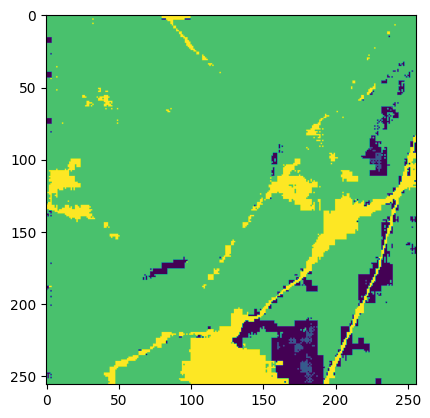

In [20]:
import cv2
# fp = '/p/project1/hai_ws4eo/liu_ch/Weak_FT/segment-anything-2/Results_1st_stage_sub_s4/FT_dofab_auxl_attcp_exact_sub_max1500_deI_mcloss/0F_1D_10C_lr1e4_cos_w5_cos95/seed_42_bs_6/wandb/offline-run-20241021_092157-n2h3qi6d/files/media/images/mask/val_masks_0_341c695bd00f3881de54.mask.png'
# fp = '/p/project1/hai_ws4eo/liu_ch/Weak_FT/segment-anything-2/Results_1st_stage_sub_s4/FT_dofab_auxl_attcp_exact_sub_max1500_deI_mcloss/0F_1D_10C_lr1e4_cos_w5_cos95/seed_42_bs_6/wandb/offline-run-20241021_092157-n2h3qi6d/files/media/images/mask/val_masks_0_fbcf450395ee65a3e998.mask.png'
fp = '/p/project1/hai_ws4eo/liu_ch/Weak_FT/segment-anything-2/Results_1st_stage_sub_s4/FT_dofab_auxl_attcp_exact_sub_max1500_deI_mcloss/0F_1D_10C_lr1e4_cos_w5_cos95/seed_42_bs_6/wandb/offline-run-20241021_092157-n2h3qi6d/files/media/images/mask/val_masks_48_a6606e96d301aba08d40.mask.png'
img = cv2.imread(fp, cv2.IMREAD_UNCHANGED)
plt.imshow(img)
img.shape

(256, 256)

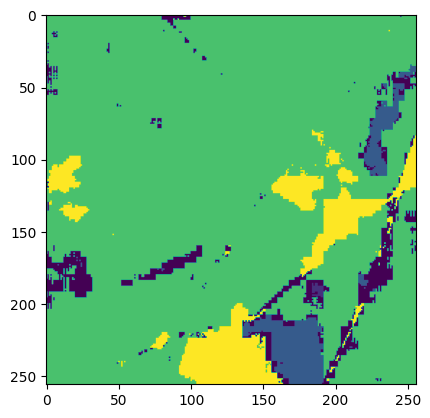

In [22]:
fp = '/p/project1/hai_ws4eo/liu_ch/Weak_FT/segment-anything-2/Results_1st_stage_sub_s4/FT_dofab_auxl_attcp_exact_sub_max1500_deI_mcloss/0F_5D_5C_lr1e4_cos_w5_cos95/seed_42_bs_6/wandb/offline-run-20241021_092146-tpme7zu1/files/media/images/mask/val_masks_48_8e9d6fabfbc979b3da95.mask.png'
img = cv2.imread(fp, cv2.IMREAD_UNCHANGED)
plt.imshow(img)
img.shape